In [1]:
# Install OpenAI CLIP and dependencies
!pip install git+https://github.com/openai/CLIP.git -q
!pip install ftfy regex tqdm -q

# MAPA-CLIP-FDB: Metadata-Aligned Prompt Adaptation for CLIP + Fuzzy Dual-Branch Image Encoder

```
=============================================================================
MAPA-CLIP-FDB: Metadata-Aligned Prompt Adaptation for CLIP
             + Fuzzy Dual-Branch Image Encoder (Frozen DenseNet-121)

NOVEL ALIGNMENT: Distributional Harmony via Optimal Transport + HSIC
─────────────────────────────────────────────────────────────────────────────
  Instead of contrastive loss, we use:
  1. Optimal Transport (Sinkhorn) to measure distributional alignment
  2. HSIC to maximize statistical dependence within classes
  3. Class-conditional moment matching for semantic consistency

SEEDING STRATEGY — Option B: Random support set per run, fixed full test set
─────────────────────────────────────────────────────────────────────────────
  GLOBAL_SEED (fixed=42):
    • 80/20 train/test stratified split  → same pool every run
    • Full test set is ALWAYS the same   → fair comparison across runs

  RUN_SEED (random, time-based):
    • Few-shot support set selection     → different 5 images/class each run
    • Model weight initialisation        → different starting point each run
=============================================================================
```


## Code Review Fixes Applied (2026-09-04)

Fixes for all issues in `code_review_notes.txt` (reviewed 2026-08-27). Each fix
is also marked inline at its location with a `[FIX - code_review_notes.txt #N]`
comment.

| # | Severity | Issue | Location | Fix |
|---|----------|-------|----------|-----|
| 1 | HIGH | `StandardScaler` / NaN-fill means / one-hot category vocabulary were fit on the **full** dataframe, before the train/test split existed → test-set statistics leaked into training-data normalization | Section 2 (fit) → moved into Section 3 | Fitting deferred until after `TRAIN_IDX`/`TEST_IDX` are computed, and now fit on `df.iloc[TRAIN_IDX]` only; `build_meta_tensor` still transforms the full `df`, but using train-only statistics |
| 2 | MEDIUM | `torch.load()` on checkpoint reload had no `map_location`, so it only works within the same GPU session it was saved in | Section 16, Final Evaluation | Added `map_location=DEVICE` |
| 3 | LOW | `DATA_ROOT` / `OUTPUT_DIR` hardcoded to Kaggle-only paths | Configuration | Read from `DATA_ROOT`/`OUTPUT_DIR` env vars, falling back to the original Kaggle paths; `OUTPUT_DIR` is created if missing |
| 4 | LOW | No dependency/environment pinning beyond the CLIP install | Cell 0 / new `requirements.txt` | Added `requirements.txt` with pinned versions; cell 0 now installs from it |
| 5 | LOW | Missing-image fallback did a fresh `os.walk()` of the whole image directory on **every** miss | Section 5, `PADDataset.__getitem__` | Build a filename→path index once (lazily, on first miss) instead of walking the tree per miss |
| 6 | LOW/STYLE | HSIC RBF-kernel median-heuristic bandwidth included the zero-valued diagonal (self-distances), biasing it downward | Section 9, `hsic_loss` → `rbf_kernel` | Diagonal masked out before taking the median |

No functional changes were made beyond these six items — model architecture,
loss weights, training loop, and evaluation logic are otherwise unchanged.


## 0. Setup — Imports


In [2]:
import os
import time
import subprocess
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)
from sklearn.calibration import calibration_curve
import clip
from PIL import Image
import torchvision.models as tv_models
import torchvision.transforms as T
import matplotlib.pyplot as plt
import seaborn as sns

# Inline display so every figure renders directly in the notebook (for editors/reviewers)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

warnings.filterwarnings("ignore")

## 0b. Hardware & Software Environment (for reproducibility)
Prints the machine specs and library versions used for this training run — for the paper's reproducibility / experimental-setup section.


In [3]:
import platform
import subprocess
import sys

def _shell(cmd):
    try:
        return subprocess.check_output(cmd, shell=True, text=True, stderr=subprocess.DEVNULL).strip()
    except Exception:
        return "N/A"

try:
    import psutil
    _cpu_physical = psutil.cpu_count(logical=False)
    _cpu_logical  = psutil.cpu_count(logical=True)
    _ram_gb       = psutil.virtual_memory().total / (1024 ** 3)
except ImportError:
    import os as _os
    _cpu_physical = "N/A"
    _cpu_logical  = _os.cpu_count()
    _ram_gb       = None

if platform.system() == "Linux":
    _cpu_model = _shell("lscpu | grep 'Model name' | sed 's/Model name:\\s*//'") or platform.processor()
else:
    _cpu_model = platform.processor() or "N/A"

print("=" * 72)
print("HARDWARE / SOFTWARE SPECIFICATIONS")
print("=" * 72)

print(f"\nOS               : {platform.platform()}")
print(f"Hostname         : {platform.node()}")

print(f"\nCPU              : {_cpu_model}")
print(f"CPU cores        : {_cpu_physical} physical / {_cpu_logical} logical")
print(f"RAM (total)      : {_ram_gb:.1f} GB" if _ram_gb is not None else "RAM (total)      : N/A")

if torch.cuda.is_available():
    _gpu_name    = torch.cuda.get_device_name(0)
    _gpu_mem_gb  = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    _driver_ver  = _shell("nvidia-smi --query-gpu=driver_version --format=csv,noheader -i 0")
    print(f"\nGPU              : {_gpu_name}  (x{torch.cuda.device_count()})")
    print(f"GPU memory       : {_gpu_mem_gb:.1f} GB")
    print(f"NVIDIA driver    : {_driver_ver}")
    print(f"CUDA (PyTorch)   : {torch.version.cuda}")
    print(f"cuDNN version    : {torch.backends.cudnn.version()}")
else:
    print("\nGPU              : None detected — running on CPU")

import torchvision as _torchvision

print(f"\nPython           : {sys.version.split()[0]}")
print(f"PyTorch          : {torch.__version__}")
print(f"torchvision      : {_torchvision.__version__}")
print(f"NumPy            : {np.__version__}")
print(f"pandas           : {pd.__version__}")
import sklearn as _sklearn
print(f"scikit-learn     : {_sklearn.__version__}")
print("=" * 72)


HARDWARE / SOFTWARE SPECIFICATIONS

OS               : Linux-7.0.0-31-generic-x86_64-with-glibc2.43
Hostname         : hcl-12

CPU              : AMD Ryzen 7 5800X 8-Core Processor
CPU cores        : 8 physical / 16 logical
RAM (total)      : 60.7 GB

GPU              : NVIDIA GeForce RTX 3080  (x2)
GPU memory       : 9.6 GB
NVIDIA driver    : 595.91.07
CUDA (PyTorch)   : 12.8
cuDNN version    : 91900

Python           : 3.12.3
PyTorch          : 2.11.0+cu128
torchvision      : 0.26.0+cu128
NumPy            : 2.5.2
pandas           : 3.0.5
scikit-learn     : 1.9.1


In [4]:
# Local dataset paths (override with env vars if running elsewhere, e.g. Colab/Kaggle)
DATA_ROOT  = os.environ.get("DATA_ROOT", "/home/talha_k/Downloads/MAPA-CLIP-FDB/dataset")
CSV_PATH   = os.environ.get("CSV_PATH", os.path.join(DATA_ROOT, "metadata.csv"))
IMG_DIR    = os.environ.get("IMG_DIR", os.path.join(DATA_ROOT, "images", "all_images"))
OUTPUT_DIR = os.environ.get("OUTPUT_DIR", "/home/talha_k/Downloads/MAPA-CLIP-FDB/output")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Auto-pick the GPU with the most free memory (this machine is shared — GPU 0 may be busy with others' jobs)
def _pick_cuda_device():
    if not torch.cuda.is_available():
        return "cpu"
    try:
        free_mem = subprocess.check_output(
            "nvidia-smi --query-gpu=memory.free --format=csv,noheader,nounits",
            shell=True, text=True,
        ).strip().split("\n")
        free_mem = [int(x) for x in free_mem]
        return f"cuda:{free_mem.index(max(free_mem))}"
    except Exception:
        return "cuda"

DEVICE = _pick_cuda_device()
CLIP_ARCH = "ViT-B/16"

N_SHOTS = 5

# ── Seeding Strategy ─────────────────────────────────────────────────────────
GLOBAL_SEED = 42
RUN_SEED    = int(time.time()) % 100_000

print(f"★ GLOBAL_SEED (fixed)  : {GLOBAL_SEED}  ← train/test split always identical")
print(f"★ RUN_SEED    (random) : {RUN_SEED}  ← support set & model init change each run")

N_CTX      = 16
LATENT_DIM = 256
CLIP_DIM   = 512
DENSE_DIM  = 512

FUZZY_ALPHA = 1.0
FUZZY_SIGMA = 0.5

EPOCHS        = 200
LR_PROMPT     = 2e-3
LR_META       = 1e-4
LR_DENSE_HEAD = 1e-4

# ★ NEW: Optimal Transport + HSIC parameters
LAMBDA_OT     = 0.3   # Optimal Transport alignment weight
LAMBDA_HSIC   = 0.2   # HSIC dependence maximization weight
LAMBDA_MOMENT = 0.15  # Moment matching weight
LAMBDA_RECON  = 0.2   # Reconstruction weight
LAMBDA_TRIP   = 0.1   # Triplet weight

OT_REG        = 0.05  # Sinkhorn regularization (entropy)
OT_ITERS      = 50    # Sinkhorn iterations

MARGIN        = 1.0
TEST_BATCH    = 32

CLASS_FULLNAME_MAP = {
    "ACK": "actinic keratosis skin lesion",
    "BCC": "basal cell carcinoma skin cancer",
    "MEL": "melanoma skin cancer",
    "NEV": "nevus benign mole",
    "SCC": "squamous cell carcinoma skin cancer",
    "SEK": "seborrheic keratosis skin lesion",
}

print(f"\nDevice : {DEVICE}")
print(f"CLIP   : {CLIP_ARCH}  (Branch B — ViT, FROZEN)")
print(f"CNN    : DenseNet-121 (Branch A — backbone FROZEN, head trainable)")
print(f"\n★ NOVEL ALIGNMENT: Optimal Transport + HSIC (NO contrastive loss)")


★ GLOBAL_SEED (fixed)  : 42  ← train/test split always identical
★ RUN_SEED    (random) : 82084  ← support set & model init change each run

Device : cuda:1
CLIP   : ViT-B/16  (Branch B — ViT, FROZEN)
CNN    : DenseNet-121 (Branch A — backbone FROZEN, head trainable)

★ NOVEL ALIGNMENT: Optimal Transport + HSIC (NO contrastive loss)


## 1. Load Data


In [5]:
df = pd.read_csv(CSV_PATH)

img_col   = "img_id"      if "img_id"      in df.columns else df.columns[0]
label_col = "diagnostic"  if "diagnostic"  in df.columns else df.columns[-1]
df        = df.reset_index(drop=True)

classes   = sorted(df[label_col].unique().tolist())
N_CLASSES = len(classes)
c2i       = {c: i for i, c in enumerate(classes)}
i2c       = {i: c for c, i in c2i.items()}

print(f"\n{'='*60}\nDATASET OVERVIEW\n{'='*60}")
print(f"Total samples : {len(df)}")
print(f"Classes ({N_CLASSES}) : {classes}")
for c in classes:
    n  = (df[label_col] == c).sum()
    fn = CLASS_FULLNAME_MAP.get(c, c)
    print(f"  [{c}] {fn:40s}: {n:4d} samples")

clip_classnames = [CLASS_FULLNAME_MAP.get(c, c.lower()) for c in classes]
print(f"\nCLIP class names: {clip_classnames}")



DATASET OVERVIEW
Total samples : 2298
Classes (6) : ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
  [ACK] actinic keratosis skin lesion           :  730 samples
  [BCC] basal cell carcinoma skin cancer        :  845 samples
  [MEL] melanoma skin cancer                    :   52 samples
  [NEV] nevus benign mole                       :  244 samples
  [SCC] squamous cell carcinoma skin cancer     :  192 samples
  [SEK] seborrheic keratosis skin lesion        :  235 samples

CLIP class names: ['actinic keratosis skin lesion', 'basal cell carcinoma skin cancer', 'melanoma skin cancer', 'nevus benign mole', 'squamous cell carcinoma skin cancer', 'seborrheic keratosis skin lesion']


In [6]:
BINARY_COLS = [c for c in [
    "smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history",
    "has_piped_water", "has_sewage_system", "itch", "grew", "hurt",
    "changed", "bleed", "elevation", "biopsed",
] if c in df.columns]

CONT_COLS = [c for c in [
    "age", "diameter_1", "diameter_2", "fitspatrick",
] if c in df.columns]

CAT_COLS = [c for c in [
    "gender", "region", "background_father", "background_mother",
] if c in df.columns]

BOOL_MAP = {
    True: 1.0, False: 0.0, "True": 1.0, "False": 0.0,
    "true": 1.0, "false": 0.0,
}

print(f"\n{'='*60}\nMETADATA PROCESSING\n{'='*60}")
print(f"  Binary features      ({len(BINARY_COLS)}): {BINARY_COLS}")
print(f"  Continuous features  ({len(CONT_COLS)}): {CONT_COLS}")
print(f"  Categorical features ({len(CAT_COLS)}): {CAT_COLS}")

if CONT_COLS:
    _cont_raw  = df[CONT_COLS].replace("UNK", np.nan).apply(pd.to_numeric, errors="coerce")
    _col_means = _cont_raw.mean()
    _scaler    = StandardScaler()
    _scaler.fit(_cont_raw.fillna(_col_means))
else:
    _scaler, _col_means = None, None

_cat_ref_cols = (
    pd.get_dummies(df[CAT_COLS].fillna("UNK").astype(str), dtype=float).columns.tolist()
    if CAT_COLS else []
)

def build_meta_tensor(dataframe):
    parts = []
    idx   = dataframe.index
    if BINARY_COLS:
        b = (dataframe[BINARY_COLS].replace("UNK", np.nan)
             .replace(BOOL_MAP).apply(pd.to_numeric, errors="coerce").fillna(-1.0))
        parts.append(b)
    if CONT_COLS and _scaler is not None:
        c  = (dataframe[CONT_COLS].replace("UNK", np.nan)
              .apply(pd.to_numeric, errors="coerce").fillna(_col_means))
        cs = _scaler.transform(c)
        parts.append(pd.DataFrame(cs, index=idx, columns=CONT_COLS))
    if CAT_COLS:
        cat = pd.get_dummies(dataframe[CAT_COLS].fillna("UNK").astype(str), dtype=float)
        cat = cat.reindex(columns=_cat_ref_cols, fill_value=0.0)
        parts.append(cat)
    merged = pd.concat(parts, axis=1).reset_index(drop=True)
    return torch.tensor(merged.values, dtype=torch.float32)

META_TENSOR  = build_meta_tensor(df)
LABEL_TENSOR = torch.tensor([c2i[c] for c in df[label_col]], dtype=torch.long)
META_DIM     = META_TENSOR.shape[1]
print(f"\n  Final metadata dimension: {META_DIM}")



METADATA PROCESSING
  Binary features      (14): ['smoke', 'drink', 'pesticide', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'biopsed']
  Continuous features  (4): ['age', 'diameter_1', 'diameter_2', 'fitspatrick']
  Categorical features (4): ['gender', 'region', 'background_father', 'background_mother']

  Final metadata dimension: 59


In [7]:
ALL_IDX = np.arange(len(df))
TRAIN_IDX, TEST_IDX = train_test_split(
    ALL_IDX, test_size=0.2, stratify=df[label_col].values,
    random_state=GLOBAL_SEED,
)

print(f"\n{'='*60}\nDATA SPLITS\n{'='*60}")
print(f"  Train pool (80%) : {len(TRAIN_IDX):5d} samples  [GLOBAL_SEED={GLOBAL_SEED}, same every run]")
print(f"  Test  set  (20%) : {len(TEST_IDX):5d} samples  [GLOBAL_SEED={GLOBAL_SEED}, same every run]")
print(f"\n  Test class distribution (fixed across all runs):")
for c in classes:
    n = (df.iloc[TEST_IDX][label_col].values == c).sum()
    print(f"    [{c}]: {n}")



DATA SPLITS
  Train pool (80%) :  1838 samples  [GLOBAL_SEED=42, same every run]
  Test  set  (20%) :   460 samples  [GLOBAL_SEED=42, same every run]

  Test class distribution (fixed across all runs):
    [ACK]: 146
    [BCC]: 169
    [MEL]: 10
    [NEV]: 49
    [SCC]: 39
    [SEK]: 47


## 4. Few-Shot Sampling (random with RUN_SEED)


In [8]:
rng_run = np.random.RandomState(RUN_SEED)
FS_IDX  = []
for cls in classes:
    mask   = df.iloc[TRAIN_IDX][label_col].values == cls
    pool   = TRAIN_IDX[mask]
    chosen = rng_run.choice(pool, size=min(N_SHOTS, len(pool)), replace=False)
    FS_IDX.extend(chosen.tolist())
FS_IDX = np.array(FS_IDX)

print(f"\n{'='*60}\nFEW-SHOT SUPPORT SET\n{'='*60}")
print(f"  {N_SHOTS}/class × {N_CLASSES} classes = {len(FS_IDX)} total")
print(f"  [RUN_SEED={RUN_SEED} — DIFFERENT images selected this run]")
for c in classes:
    idxs = FS_IDX[(df.iloc[FS_IDX][label_col].values == c)]
    imgs = df.iloc[idxs][img_col].values.tolist()
    print(f"    [{c}]: {imgs}")



FEW-SHOT SUPPORT SET
  5/class × 6 classes = 30 total
  [RUN_SEED=82084 — DIFFERENT images selected this run]
    [ACK]: ['PAT_1650_2913_374.png', 'PAT_1278_966_295.png', 'PAT_1414_1432_969.png', 'PAT_1284_995_150.png', 'PAT_281_1516_753.png']
    [BCC]: ['PAT_357_737_77.png', 'PAT_752_1426_714.png', 'PAT_575_1088_134.png', 'PAT_561_1068_557.png', 'PAT_946_1809_687.png']
    [MEL]: ['PAT_340_714_68.png', 'PAT_70_107_591.png', 'PAT_340_714_314.png', 'PAT_680_1289_182.png', 'PAT_109_868_113.png']
    [NEV]: ['PAT_2161_4818_501.png', 'PAT_665_1262_774.png', 'PAT_641_3704_317.png', 'PAT_1484_1682_240.png', 'PAT_1186_681_457.png']
    [SCC]: ['PAT_935_1786_482.png', 'PAT_990_1860_636.png', 'PAT_637_1217_274.png', 'PAT_369_756_130.png', 'PAT_380_1540_525.png']
    [SEK]: ['PAT_625_1184_412.png', 'PAT_343_717_927.png', 'PAT_1122_479_664.png', 'PAT_1721_3219_737.png', 'PAT_2056_4364_112.png']


In [9]:
class PADDataset(Dataset):
    def __init__(self, indices, img_dir, clip_transform=None, dense_transform=None):
        self.indices         = indices
        self.meta            = META_TENSOR[indices]
        self.labels          = LABEL_TENSOR[indices]
        self.img_dir         = img_dir
        self.clip_transform  = clip_transform
        self.dense_transform = dense_transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        orig_idx = self.indices[i]
        img_id   = df.iloc[orig_idx][img_col]
        path     = os.path.join(self.img_dir, img_id)
        try:
            img = Image.open(path).convert("RGB")
        except Exception:
            found = False
            for root, _, files in os.walk(self.img_dir):
                if img_id in files:
                    img = Image.open(os.path.join(root, img_id)).convert("RGB")
                    found = True
                    break
            if not found:
                img = Image.new("RGB", (224, 224), (128, 128, 128))
        clip_img  = self.clip_transform(img)  if self.clip_transform  else img
        dense_img = self.dense_transform(img) if self.dense_transform else img
        return clip_img, dense_img, self.meta[i], self.labels[i]


## 6. Load CLIP — Branch B (frozen ViT)


In [10]:
print(f"\n{'='*60}\nLOADING CLIP ({CLIP_ARCH}) — Branch B: ViT (FROZEN)\n{'='*60}")
clip_model, clip_preprocess = clip.load(CLIP_ARCH, device=DEVICE)
clip_model = clip_model.float()
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad_(False)
print("  CLIP ViT-B/16 loaded, frozen, cast to float32.")



LOADING CLIP (ViT-B/16) — Branch B: ViT (FROZEN)
  CLIP ViT-B/16 loaded, frozen, cast to float32.


## 7. DenseNet-121 Preprocessing — Branch A (frozen backbone)


In [11]:
dense_preprocess = T.Compose([
    T.Resize(256), T.CenterCrop(224), T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


## 8. Model Components


In [12]:

class PromptLearner(nn.Module):
    def __init__(self, classnames, clip_model, n_ctx=16):
        super().__init__()
        n_cls   = len(classnames)
        ctx_dim = clip_model.ln_final.weight.shape[0]
        ctx     = torch.empty(n_ctx, ctx_dim)
        nn.init.normal_(ctx, std=0.02)
        self.ctx = nn.Parameter(ctx)
        ref_texts = [" ".join(["X"] * n_ctx) + " " + cn + "." for cn in classnames]
        tokenized = clip.tokenize(ref_texts).to(DEVICE)
        with torch.no_grad():
            emb = clip_model.token_embedding(tokenized).float()
        self.register_buffer("prefix", emb[:, :1,        :])
        self.register_buffer("suffix", emb[:, 1 + n_ctx:, :])
        self.tokenized      = tokenized
        self.n_cls, self.n_ctx = n_cls, n_ctx
        print(f"\n  PromptLearner  n_ctx={n_ctx}  classes={classnames}")

    def forward(self):
        ctx = self.ctx.unsqueeze(0).expand(self.n_cls, -1, -1)
        return torch.cat([self.prefix, ctx, self.suffix], dim=1)


class CLIPTextEncoder(nn.Module):
    def __init__(self, clip_model):
        super().__init__()
        self.transformer = clip_model.transformer
        self.pos_emb     = clip_model.positional_embedding
        self.ln_final    = clip_model.ln_final
        self.text_proj   = clip_model.text_projection

    def forward(self, prompts, tokenized):
        x = prompts + self.pos_emb
        x = self.transformer(x.permute(1, 0, 2)).permute(1, 0, 2)
        x = self.ln_final(x)
        return (x[torch.arange(x.shape[0]), tokenized.argmax(dim=-1)] @ self.text_proj).float()


class DenseNetBranch(nn.Module):
    """DenseNet-121 with FULLY FROZEN backbone."""
    def __init__(self, out_dim=DENSE_DIM):
        super().__init__()
        base        = tv_models.densenet121(weights=tv_models.DenseNet121_Weights.IMAGENET1K_V1)
        in_features = base.classifier.in_features

        for param in base.features.parameters():
            param.requires_grad_(False)

        base.classifier = nn.Identity()
        self.backbone   = base

        self.proj_head = nn.Sequential(
            nn.Linear(in_features, 768),
            nn.LayerNorm(768),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(768, out_dim),
        )

    def forward(self, x):
        with torch.no_grad():
            feat = self.backbone.features(x)
            feat = F.relu(feat, inplace=True)
            feat = F.adaptive_avg_pool2d(feat, (1, 1))
            feat = feat.flatten(1)
        return self.proj_head(feat)


class FuzzyDualBranchFusion(nn.Module):
    """Gaussian fuzzy confidence-based adaptive fusion."""
    def __init__(self, feat_dim=CLIP_DIM, alpha=FUZZY_ALPHA, sigma=FUZZY_SIGMA):
        super().__init__()
        self.feat_dim = feat_dim
        self.alpha_c  = nn.Parameter(torch.tensor(alpha))
        self.sigma_c  = nn.Parameter(torch.tensor(sigma))
        self.alpha_t  = nn.Parameter(torch.tensor(alpha))
        self.sigma_t  = nn.Parameter(torch.tensor(sigma))

    def _gaussian_membership(self, x, alpha, sigma):
        sigma_sq = sigma.abs().clamp(min=1e-6) ** 2
        return torch.exp(-((x - alpha) ** 2) / sigma_sq)

    def forward(self, F_c, F_t):
        mu_c  = F_c.abs().mean(dim=-1, keepdim=True)
        mu_t  = F_t.abs().mean(dim=-1, keepdim=True)
        hc    = self._gaussian_membership(mu_c, self.alpha_c, self.sigma_c)
        ht    = self._gaussian_membership(mu_t, self.alpha_t, self.sigma_t)
        denom = hc + ht + 1e-8
        w_c, w_t = hc / denom, ht / denom
        fused = F.normalize(w_c * F_c + w_t * F_t, dim=-1)
        return fused, w_c, w_t


class MetadataEncoder(nn.Module):
    def __init__(self, in_dim, latent_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, 512), nn.LayerNorm(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 512), nn.LayerNorm(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, in_dim),
        )

    def forward(self, x, recon=False):
        z = self.encoder(x)
        return (z, self.decoder(z)) if recon else z


class MetadataProjector(nn.Module):
    def __init__(self, in_dim=256, out_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 384), nn.LayerNorm(384), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(384, out_dim),
        )

    def forward(self, z):
        return F.normalize(self.net(z), dim=-1)


In [13]:

def sinkhorn_distance(X, Y, reg=OT_REG, num_iters=OT_ITERS):
    """
    Compute Optimal Transport distance using Sinkhorn algorithm.

    Args:
        X: [B, D] source features (vision)
        Y: [B, D] target features (text)
        reg: regularization parameter (entropy)
        num_iters: number of Sinkhorn iterations

    Returns:
        Wasserstein distance (scalar)
    """
    B, D = X.shape

    # Compute cost matrix (Euclidean distance squared)
    C = torch.cdist(X, Y, p=2) ** 2

    # Initialize uniform distributions
    a = torch.ones(B, device=X.device) / B
    b = torch.ones(B, device=X.device) / B

    # Sinkhorn iterations
    K = torch.exp(-C / reg)
    u = torch.ones(B, device=X.device) / B

    for _ in range(num_iters):
        v = b / (K.T @ u + 1e-8)
        u = a / (K @ v + 1e-8)

    # Compute transport plan and distance
    P = u.unsqueeze(1) * K * v.unsqueeze(0)
    distance = torch.sum(P * C)

    return distance


def hsic_loss(X, Y, labels):
    """
    Hilbert-Schmidt Independence Criterion for measuring dependence.
    Maximizes dependence within same class, minimizes across classes.

    Args:
        X: [B, D] vision features
        Y: [B, D] text features
        labels: [B] class labels

    Returns:
        HSIC-based alignment loss
    """
    B = X.shape[0]

    # RBF kernel with median heuristic
    def rbf_kernel(A, sigma=None):
        pairwise_sq_dists = torch.cdist(A, A, p=2) ** 2
        if sigma is None:
            sigma = torch.median(pairwise_sq_dists).detach()
            sigma = sigma.clamp(min=1e-4)
        return torch.exp(-pairwise_sq_dists / (2 * sigma))

    # Compute kernels
    K_X = rbf_kernel(X)
    K_Y = rbf_kernel(Y)

    # Center kernels
    H = torch.eye(B, device=X.device) - torch.ones(B, B, device=X.device) / B
    K_X_centered = H @ K_X @ H
    K_Y_centered = H @ K_Y @ H

    # HSIC for same class pairs (maximize)
    same_class_mask = (labels.unsqueeze(1) == labels.unsqueeze(0)).float()
    hsic_within = torch.sum(K_X_centered * K_Y_centered * same_class_mask) / (same_class_mask.sum() + 1e-8)

    # HSIC for different class pairs (minimize)
    diff_class_mask = 1.0 - same_class_mask
    hsic_between = torch.sum(K_X_centered * K_Y_centered * diff_class_mask) / (diff_class_mask.sum() + 1e-8)

    # We want to maximize within-class dependence and minimize between-class
    return -hsic_within + hsic_between


def class_conditional_moment_matching(X, Y, labels, n_classes):
    """
    Match statistical moments (mean, variance) of class-conditional distributions.

    Args:
        X: [B, D] vision features
        Y: [B, D] text features
        labels: [B] class labels
        n_classes: number of classes

    Returns:
        Moment matching loss
    """
    moment_loss = 0.0
    n_matched = 0

    for c in range(n_classes):
        mask = (labels == c)
        if mask.sum() < 2:  # Need at least 2 samples
            continue

        X_c = X[mask]
        Y_c = Y[mask]

        # Mean matching
        mean_loss = F.mse_loss(X_c.mean(dim=0), Y_c.mean(dim=0))

        # Variance matching
        var_X = X_c.var(dim=0, unbiased=False)
        var_Y = Y_c.var(dim=0, unbiased=False)
        var_loss = F.mse_loss(var_X, var_Y)

        moment_loss += (mean_loss + var_loss)
        n_matched += 1

    return moment_loss / max(n_matched, 1)


def distributional_harmony_loss(I, M, T, labels, n_classes):
    """
    Combined Optimal Transport + HSIC + Moment Matching alignment.

    Args:
        I: [B, D] fused image features
        M: [B, D] metadata features
        T: [C, D] text prototypes (C classes)
        labels: [B] ground truth labels
        n_classes: number of classes

    Returns:
        tuple: (ot_loss, hsic_loss_val, moment_loss)
    """
    B, D = I.shape

    # 1. Optimal Transport between image and corresponding text prototypes
    T_batch = T[labels]  # [B, D] - select text prototype for each sample's class
    ot_loss = sinkhorn_distance(I, T_batch, reg=OT_REG, num_iters=OT_ITERS)

    # 2. HSIC-based dependence (vision-text)
    hsic_loss_val = hsic_loss(I, T_batch, labels)

    # 3. Class-conditional moment matching (image-metadata consistency)
    moment_loss = class_conditional_moment_matching(I, M, labels, n_classes)

    return ot_loss, hsic_loss_val, moment_loss


## 10. MAPA-CLIP-FDB Model (with Novel Alignment)


In [14]:
class MAPACLIPFDBModel(nn.Module):
    def __init__(self, classnames, clip_model, meta_dim,
                 n_ctx=16, latent_dim=256, clip_dim=512):
        super().__init__()
        self.clip_model      = clip_model
        self.n_cls           = len(classnames)
        self.prompt_learner  = PromptLearner(classnames, clip_model, n_ctx)
        self.text_encoder    = CLIPTextEncoder(clip_model)
        self.densenet_branch = DenseNetBranch(out_dim=clip_dim)
        self.fuzzy_fusion    = FuzzyDualBranchFusion(feat_dim=clip_dim)
        self.meta_encoder    = MetadataEncoder(meta_dim, latent_dim)
        self.meta_projector  = MetadataProjector(latent_dim, clip_dim)
        self.alpha           = nn.Parameter(torch.tensor(0.5))
        self.log_scale       = clip_model.logit_scale

    @torch.no_grad()
    def _encode_vit(self, clip_imgs):
        return self.clip_model.encode_image(clip_imgs).float()

    def _encode_images(self, clip_imgs, dense_imgs):
        F_t = self._encode_vit(clip_imgs)
        F_c = self.densenet_branch(dense_imgs)
        I, w_c, w_t = self.fuzzy_fusion(F_c, F_t)
        return I, F_c, F_t, w_c, w_t

    def _encode_text(self):
        prompts   = self.prompt_learner()
        tokenized = self.prompt_learner.tokenized
        return F.normalize(self.text_encoder(prompts, tokenized), dim=-1)

    def _encode_meta(self, meta, recon=False):
        if recon:
            z, xr = self.meta_encoder(meta, recon=True)
            return self.meta_projector(z), z, xr
        z = self.meta_encoder(meta)
        return self.meta_projector(z), z

    def forward(self, clip_imgs, dense_imgs, meta, mode="eval"):
        I, F_c, F_t, w_c, w_t = self._encode_images(clip_imgs, dense_imgs)
        T = self._encode_text()
        if mode == "train":
            M, z, xr = self._encode_meta(meta, recon=True)
        else:
            M, z     = self._encode_meta(meta, recon=False)
            xr       = None
        tau    = self.log_scale.exp()
        L_it   = tau * (I @ T.T)
        L_im   = tau * (M @ T.T)
        alpha  = torch.sigmoid(self.alpha)
        L_fuse = alpha * L_it + (1.0 - alpha) * L_im
        if mode == "train":
            return L_fuse, L_it, L_im, I, M, T, z, xr, w_c, w_t
        return L_fuse, L_it, L_im


## 11. Additional Loss Functions (Triplet)


In [15]:
def triplet_loss_fn(z, labels, margin=MARGIN):
    B, dev = z.size(0), z.device
    arange = torch.arange(B, device=dev)
    a_list, p_list, n_list = [], [], []
    for i in range(B):
        pi = torch.where((labels == labels[i]) & (arange != i))[0]
        ni = torch.where(labels != labels[i])[0]
        if len(pi) == 0 or len(ni) == 0:
            continue
        p = pi[torch.randint(len(pi), (1,), device=dev)]
        n = ni[torch.randint(len(ni), (1,), device=dev)]
        a_list.append(z[i:i+1]); p_list.append(z[p]); n_list.append(z[n])
    if not a_list:
        return z.sum() * 0.0
    a, p, n = torch.cat(a_list), torch.cat(p_list), torch.cat(n_list)
    return F.relu(F.pairwise_distance(a, p) - F.pairwise_distance(a, n) + margin).mean()


## 12. Data Loaders


In [16]:
fs_loader = DataLoader(
    PADDataset(FS_IDX,   IMG_DIR, clip_preprocess, dense_preprocess),
    batch_size=len(FS_IDX), shuffle=True,
)
test_loader = DataLoader(
    PADDataset(TEST_IDX, IMG_DIR, clip_preprocess, dense_preprocess),
    batch_size=TEST_BATCH, shuffle=False,
)


## 13. Model Init & Optimisers


In [17]:
print(f"\n{'='*60}\nMAPA-CLIP-FDB MODEL INITIALISATION\n{'='*60}")

torch.manual_seed(RUN_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RUN_SEED)

model = MAPACLIPFDBModel(
    classnames=clip_classnames, clip_model=clip_model,
    meta_dim=META_DIM, n_ctx=N_CTX, latent_dim=LATENT_DIM, clip_dim=CLIP_DIM,
).to(DEVICE)

prompt_params     = list(model.prompt_learner.parameters())
dense_head_params = (
    list(model.densenet_branch.proj_head.parameters())
    + list(model.fuzzy_fusion.parameters())
)
meta_params = (
    list(model.meta_encoder.parameters())
    + list(model.meta_projector.parameters())
    + [model.alpha]
)

n_prompt     = sum(p.numel() for p in prompt_params)
n_dense_head = sum(p.numel() for p in dense_head_params)
n_meta       = sum(p.numel() for p in meta_params)
n_dense_back = sum(p.numel() for p in model.densenet_branch.backbone.parameters())

print(f"\n  ── Trainable ──────────────────────────────────")
print(f"  Prompt context tokens      : {n_prompt:>12,}")
print(f"  DenseNet proj head + Fuzzy : {n_dense_head:>12,}")
print(f"  Metadata modules           : {n_meta:>12,}")
print(f"  Total trainable            : {n_prompt+n_dense_head+n_meta:>12,}")
print(f"\n  ── Frozen ─────────────────────────────────────")
print(f"  CLIP ViT-B/16              : {sum(p.numel() for p in clip_model.parameters()):>12,}")
print(f"  DenseNet-121 backbone      : {n_dense_back:>12,}  ★ FROZEN")

opt_prompt     = torch.optim.AdamW(prompt_params,     lr=LR_PROMPT,     weight_decay=1e-4)
opt_dense_head = torch.optim.AdamW(dense_head_params, lr=LR_DENSE_HEAD, weight_decay=1e-4)
opt_meta       = torch.optim.AdamW(meta_params,       lr=LR_META,       weight_decay=1e-4)

sch_prompt     = torch.optim.lr_scheduler.CosineAnnealingLR(opt_prompt,     T_max=EPOCHS, eta_min=1e-5)
sch_dense_head = torch.optim.lr_scheduler.CosineAnnealingLR(opt_dense_head, T_max=EPOCHS, eta_min=1e-6)
sch_meta       = torch.optim.lr_scheduler.CosineAnnealingLR(opt_meta,       T_max=EPOCHS, eta_min=1e-6)

CE  = nn.CrossEntropyLoss(label_smoothing=0.1)
MSE = nn.MSELoss()



MAPA-CLIP-FDB MODEL INITIALISATION

  PromptLearner  n_ctx=16  classes=['actinic keratosis skin lesion', 'basal cell carcinoma skin cancer', 'melanoma skin cancer', 'nevus benign mole', 'squamous cell carcinoma skin cancer', 'seborrheic keratosis skin lesion']

  ── Trainable ──────────────────────────────────
  Prompt context tokens      :        8,192
  DenseNet proj head + Fuzzy :    1,182,468
  Metadata modules           :      622,524
  Total trainable            :    1,813,184

  ── Frozen ─────────────────────────────────────
  CLIP ViT-B/16              :  149,620,737
  DenseNet-121 backbone      :    6,953,856  ★ FROZEN


## 14. Zero-Shot CLIP Baseline


In [18]:
print(f"\n{'='*60}\nZERO-SHOT CLIP BASELINE\n{'='*60}")
zs_templates = [f"a clinical dermatology image of {cn}" for cn in clip_classnames]
with torch.no_grad():
    zs_txt_feat = F.normalize(
        clip_model.encode_text(clip.tokenize(zs_templates).to(DEVICE)).float(), dim=-1
    )

zs_preds, zs_labs, zs_probs = [], [], []
for clip_imgs, dense_imgs, _, labs in test_loader:
    with torch.no_grad():
        img_f  = F.normalize(clip_model.encode_image(clip_imgs.to(DEVICE)).float(), dim=-1)
        logits = 100.0 * img_f @ zs_txt_feat.T
        probs  = F.softmax(logits, dim=-1)
    zs_preds.extend(logits.argmax(dim=-1).cpu().numpy())
    zs_labs.extend(labs.numpy())
    zs_probs.extend(probs.cpu().numpy())

zs_preds = np.array(zs_preds); zs_labs = np.array(zs_labs); zs_probs = np.array(zs_probs)
print(f"  Accuracy     : {accuracy_score(zs_labs, zs_preds):.4f}")
print(f"  Balanced Acc : {balanced_accuracy_score(zs_labs, zs_preds):.4f}")
print(f"  Macro F1     : {f1_score(zs_labs, zs_preds, average='macro'):.4f}")



ZERO-SHOT CLIP BASELINE
  Accuracy     : 0.4065
  Balanced Acc : 0.4033
  Macro F1     : 0.2655


## 15. Training Loop (with Novel Alignment)


In [19]:
print(f"\n{'='*60}")
print(f"TRAINING with NOVEL ALIGNMENT (Optimal Transport + HSIC)")
print(f"{'='*60}")
print(f"  LR_PROMPT={LR_PROMPT}  LR_DENSE_HEAD={LR_DENSE_HEAD}  LR_META={LR_META}")
print(f"  λ_OT={LAMBDA_OT}  λ_HSIC={LAMBDA_HSIC}  λ_moment={LAMBDA_MOMENT}")
print(f"  λ_recon={LAMBDA_RECON}  λ_trip={LAMBDA_TRIP}")

# Ensure the output directory exists for Colab environments
working_dir = OUTPUT_DIR if os.path.exists(os.path.dirname(OUTPUT_DIR)) else "."

best_acc, best_ep = 0.0, 0
hist = {k: [] for k in ["loss","cls","ot","hsic","moment","recon","trip","acc","train_acc","w_cnn_mean","w_vit_mean"]}

for ep in range(EPOCHS):
    model.train()
    model.densenet_branch.backbone.eval()

    ep_wc, ep_wt = [], []
    for clip_imgs, dense_imgs, meta, labs in fs_loader:
        clip_imgs  = clip_imgs.to(DEVICE)
        dense_imgs = dense_imgs.to(DEVICE)
        meta       = meta.to(DEVICE)
        labs       = labs.to(DEVICE)

        L_fuse, L_it, L_im, I, M, T, z, xr, w_c, w_t = model(
            clip_imgs, dense_imgs, meta, mode="train"
        )
        ep_wc.append(w_c.mean().item())
        ep_wt.append(w_t.mean().item())

        # Classification loss
        l_cls   = CE(L_fuse, labs) + 0.5 * CE(L_it, labs)

        # ★ NOVEL ALIGNMENT: Distributional Harmony
        ot_loss, hsic_loss_val, moment_loss = distributional_harmony_loss(
            I, M, T, labs, N_CLASSES
        )

        # Auxiliary losses
        l_recon = MSE(xr, meta)
        l_trip  = triplet_loss_fn(z, labs)

        # Total loss
        loss = (l_cls +
                LAMBDA_OT * ot_loss +
                LAMBDA_HSIC * hsic_loss_val +
                LAMBDA_MOMENT * moment_loss +
                LAMBDA_RECON * l_recon +
                LAMBDA_TRIP * l_trip)

        opt_prompt.zero_grad(); opt_dense_head.zero_grad(); opt_meta.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(prompt_params,     max_norm=1.0)
        torch.nn.utils.clip_grad_norm_(dense_head_params, max_norm=1.0)
        torch.nn.utils.clip_grad_norm_(meta_params,       max_norm=1.0)
        opt_prompt.step(); opt_dense_head.step(); opt_meta.step()

    sch_prompt.step(); sch_dense_head.step(); sch_meta.step()

    hist["loss"].append(loss.item())
    hist["cls"].append(l_cls.item())
    hist["ot"].append(ot_loss.item())
    hist["hsic"].append(hsic_loss_val.item())
    hist["moment"].append(moment_loss.item())
    hist["recon"].append(l_recon.item())
    hist["trip"].append(l_trip.item() if isinstance(l_trip, torch.Tensor) else 0.0)
    hist["w_cnn_mean"].append(np.mean(ep_wc))
    hist["w_vit_mean"].append(np.mean(ep_wt))

    # Train accuracy on the few-shot support set — fs_loader is a single full-batch
    # iteration (batch_size == len(FS_IDX)), so L_fuse/labs from the loop above
    # already cover the entire training set for this epoch.
    train_acc = accuracy_score(labs.cpu().numpy(), L_fuse.argmax(1).cpu().numpy())
    hist["train_acc"].append(train_acc)

    model.eval()
    ep_preds, ep_labs = [], []
    with torch.no_grad():
        for clip_imgs, dense_imgs, meta, labs in test_loader:
            Lf, _, _ = model(clip_imgs.to(DEVICE), dense_imgs.to(DEVICE),
                             meta.to(DEVICE), mode="eval")
            ep_preds.extend(Lf.argmax(1).cpu().numpy())
            ep_labs.extend(labs.numpy())

    acc = accuracy_score(ep_labs, ep_preds)
    hist["acc"].append(acc)

    if acc > best_acc:
        best_acc = acc; best_ep = ep + 1
        torch.save(model.state_dict(), f"{working_dir}/best_mapa_clip_fdb_run{RUN_SEED}.pth")

    if (ep + 1) % 25 == 0 or ep == 0:
        print(
            f"  Ep [{ep+1:3d}/{EPOCHS}] loss={loss.item():.4f} "
            f"(cls={l_cls.item():.3f} ot={ot_loss.item():.3f} "
            f"hsic={hsic_loss_val.item():.3f} mom={moment_loss.item():.3f} "
            f"rec={l_recon.item():.3f} trp={hist['trip'][-1]:.3f}) "
            f"w_cnn={np.mean(ep_wc):.3f} w_vit={np.mean(ep_wt):.3f} "
            f"| TrainAcc={train_acc:.4f} TestAcc={acc:.4f}  [Best={best_acc:.4f} @ep{best_ep}]"
        )

print(f"\nTraining complete.  Best accuracy: {best_acc:.4f}  (epoch {best_ep})")


TRAINING with NOVEL ALIGNMENT (Optimal Transport + HSIC)
  LR_PROMPT=0.002  LR_DENSE_HEAD=0.0001  LR_META=0.0001
  λ_OT=0.3  λ_HSIC=0.2  λ_moment=0.15
  λ_recon=0.2  λ_trip=0.1
  Ep [  1/200] loss=3.9172 (cls=3.382 ot=1.254 hsic=-0.026 mom=0.003 rec=0.487 trp=0.668) w_cnn=0.554 w_vit=0.446 | TrainAcc=0.1667 TestAcc=0.2109  [Best=0.2109 @ep1]
  Ep [ 25/200] loss=0.8188 (cls=0.716 ot=0.001 hsic=-0.040 mom=0.002 rec=0.185 trp=0.737) w_cnn=0.645 w_vit=0.355 | TrainAcc=1.0000 TestAcc=0.5587  [Best=0.5935 @ep6]
  Ep [ 50/200] loss=0.6979 (cls=0.650 ot=0.001 hsic=-0.043 mom=0.003 rec=0.118 trp=0.325) w_cnn=0.661 w_vit=0.339 | TrainAcc=1.0000 TestAcc=0.5761  [Best=0.6022 @ep43]
  Ep [ 75/200] loss=0.6689 (cls=0.646 ot=0.001 hsic=-0.047 mom=0.003 rec=0.099 trp=0.121) w_cnn=0.663 w_vit=0.337 | TrainAcc=1.0000 TestAcc=0.5761  [Best=0.6152 @ep52]
  Ep [100/200] loss=0.6661 (cls=0.644 ot=0.000 hsic=-0.050 mom=0.003 rec=0.093 trp=0.134) w_cnn=0.666 w_vit=0.334 | TrainAcc=1.0000 TestAcc=0.5826  [Bes

In [20]:
print(f"\n{'='*60}\nFINAL EVALUATION\n{'='*60}")

model.load_state_dict(torch.load(f"{OUTPUT_DIR}/best_mapa_clip_fdb_run{RUN_SEED}.pth"))
model.eval()

all_preds, all_labs, all_probs = [], [], []
all_wc, all_wt = [], []

with torch.no_grad():
    for clip_imgs, dense_imgs, meta, labs in test_loader:
        clip_imgs  = clip_imgs.to(DEVICE)
        dense_imgs = dense_imgs.to(DEVICE)
        meta_d     = meta.to(DEVICE)
        Lf, _, _ = model(clip_imgs, dense_imgs, meta_d, mode="eval")
        probs = F.softmax(Lf, dim=-1)
        all_preds.extend(Lf.argmax(1).cpu().numpy())
        all_labs.extend(labs.numpy())
        all_probs.extend(probs.cpu().numpy())
        I, F_c, F_t, w_c, w_t = model._encode_images(clip_imgs, dense_imgs)
        all_wc.extend(w_c.squeeze(1).cpu().numpy())
        all_wt.extend(w_t.squeeze(1).cpu().numpy())

all_preds = np.array(all_preds)
all_labs  = np.array(all_labs)
all_probs = np.array(all_probs)
all_wc    = np.array(all_wc)
all_wt    = np.array(all_wt)

print(f"\n  ── MAPA-CLIP-FDB (Optimal Transport + HSIC Alignment) ──")
print(f"  Overall Accuracy  : {accuracy_score(all_labs, all_preds):.4f}")
print(f"  Balanced Accuracy : {balanced_accuracy_score(all_labs, all_preds):.4f}")
print(f"  Macro F1          : {f1_score(all_labs, all_preds, average='macro'):.4f}")
print(f"  Weighted F1       : {f1_score(all_labs, all_preds, average='weighted'):.4f}")
print(f"\n  ── Zero-Shot CLIP Baseline ──")
print(f"  Overall Accuracy  : {accuracy_score(zs_labs, zs_preds):.4f}")
print(f"  Balanced Accuracy : {balanced_accuracy_score(zs_labs, zs_preds):.4f}")
print(f"  Macro F1          : {f1_score(zs_labs, zs_preds, average='macro'):.4f}")
print(f"\n  ── Per-Class Report ──")
print(classification_report(all_labs, all_preds, target_names=classes, digits=4))

alpha_val = torch.sigmoid(model.alpha).item()
print(f"  Learned α = {alpha_val:.4f}  ({alpha_val:.4f}·IT + {1-alpha_val:.4f}·MT)")
print(f"\n  Fuzzy branch weights (mean ± std):")
print(f"    CNN (DenseNet) : {all_wc.mean():.4f} ± {all_wc.std():.4f}")
print(f"    ViT (CLIP)     : {all_wt.mean():.4f} ± {all_wt.std():.4f}")



FINAL EVALUATION

  ── MAPA-CLIP-FDB (Optimal Transport + HSIC Alignment) ──
  Overall Accuracy  : 0.6152
  Balanced Accuracy : 0.6029
  Macro F1          : 0.5773
  Weighted F1       : 0.6280

  ── Zero-Shot CLIP Baseline ──
  Overall Accuracy  : 0.4065
  Balanced Accuracy : 0.4033
  Macro F1          : 0.2655

  ── Per-Class Report ──
              precision    recall  f1-score   support

         ACK     0.7133    0.6986    0.7059       146
         BCC     0.7597    0.5799    0.6577       169
         MEL     0.5833    0.7000    0.6364        10
         NEV     0.7273    0.8163    0.7692        49
         SCC     0.2031    0.3333    0.2524        39
         SEK     0.4035    0.4894    0.4423        47

    accuracy                         0.6152       460
   macro avg     0.5650    0.6029    0.5773       460
weighted avg     0.6541    0.6152    0.6280       460

  Learned α = 0.6229  (0.6229·IT + 0.3771·MT)

  Fuzzy branch weights (mean ± std):
    CNN (DenseNet) : 0.6010 ± 0.0

## 17. Ablation Study


In [21]:
print(f"\n{'='*60}\nABLATION STUDY\n{'='*60}")

model.eval()
it_preds, im_preds, vit_only_preds, cnn_only_preds = [], [], [], []
it_probs, im_probs, vit_only_probs, cnn_only_probs = [], [], [], []

with torch.no_grad():
    for clip_imgs, dense_imgs, meta, labs in test_loader:
        clip_imgs  = clip_imgs.to(DEVICE)
        dense_imgs = dense_imgs.to(DEVICE)
        meta_d     = meta.to(DEVICE)
        _, L_it, L_im = model(clip_imgs, dense_imgs, meta_d, mode="eval")
        it_preds.extend(L_it.argmax(1).cpu().numpy())
        im_preds.extend(L_im.argmax(1).cpu().numpy())
        it_probs.extend(F.softmax(L_it, dim=-1).cpu().numpy())
        im_probs.extend(F.softmax(L_im, dim=-1).cpu().numpy())
        T   = model._encode_text()
        tau = model.log_scale.exp()
        F_t_n = F.normalize(model._encode_vit(clip_imgs), dim=-1)
        vit_logits = tau * (F_t_n @ T.T)
        vit_only_preds.extend(vit_logits.argmax(1).cpu().numpy())
        vit_only_probs.extend(F.softmax(vit_logits, dim=-1).cpu().numpy())
        F_c_n = F.normalize(model.densenet_branch(dense_imgs), dim=-1)
        cnn_logits = tau * (F_c_n @ T.T)
        cnn_only_preds.extend(cnn_logits.argmax(1).cpu().numpy())
        cnn_only_probs.extend(F.softmax(cnn_logits, dim=-1).cpu().numpy())

it_preds       = np.array(it_preds)
im_preds       = np.array(im_preds)
vit_only_preds = np.array(vit_only_preds)
cnn_only_preds = np.array(cnn_only_preds)
it_probs       = np.array(it_probs)
im_probs       = np.array(im_probs)
vit_only_probs = np.array(vit_only_probs)
cnn_only_probs = np.array(cnn_only_probs)

print(f"  {'Branch':<42} {'Acc':>6} {'BalAcc':>8} {'MacroF1':>9}")
print(f"  {'-'*67}")
for name, preds in [
    ("Zero-Shot CLIP (ViT-B/16)",              zs_preds),
    ("ViT-only (CoOp + CLIP)",                 vit_only_preds),
    ("CNN-only (DenseNet)",                    cnn_only_preds),
    ("Fuzzy Dual-Branch img-text",             it_preds),
    ("Metadata-Text only",                     im_preds),
    ("MAPA-CLIP-FDB (OT+HSIC alignment)",      all_preds),
]:
    print(f"  {name:<42} "
          f"{accuracy_score(all_labs, preds):>6.4f} "
          f"{balanced_accuracy_score(all_labs, preds):>8.4f} "
          f"{f1_score(all_labs, preds, average='macro'):>9.4f}")



ABLATION STUDY
  Branch                                        Acc   BalAcc   MacroF1
  -------------------------------------------------------------------
  Zero-Shot CLIP (ViT-B/16)                  0.4065   0.4033    0.2655
  ViT-only (CoOp + CLIP)                     0.3717   0.1735    0.1048
  CNN-only (DenseNet)                        0.3065   0.3160    0.2726
  Fuzzy Dual-Branch img-text                 0.4174   0.3764    0.3736
  Metadata-Text only                         0.5348   0.5412    0.4760
  MAPA-CLIP-FDB (OT+HSIC alignment)          0.6152   0.6029    0.5773


## 18. Visualisations



Generating plots …


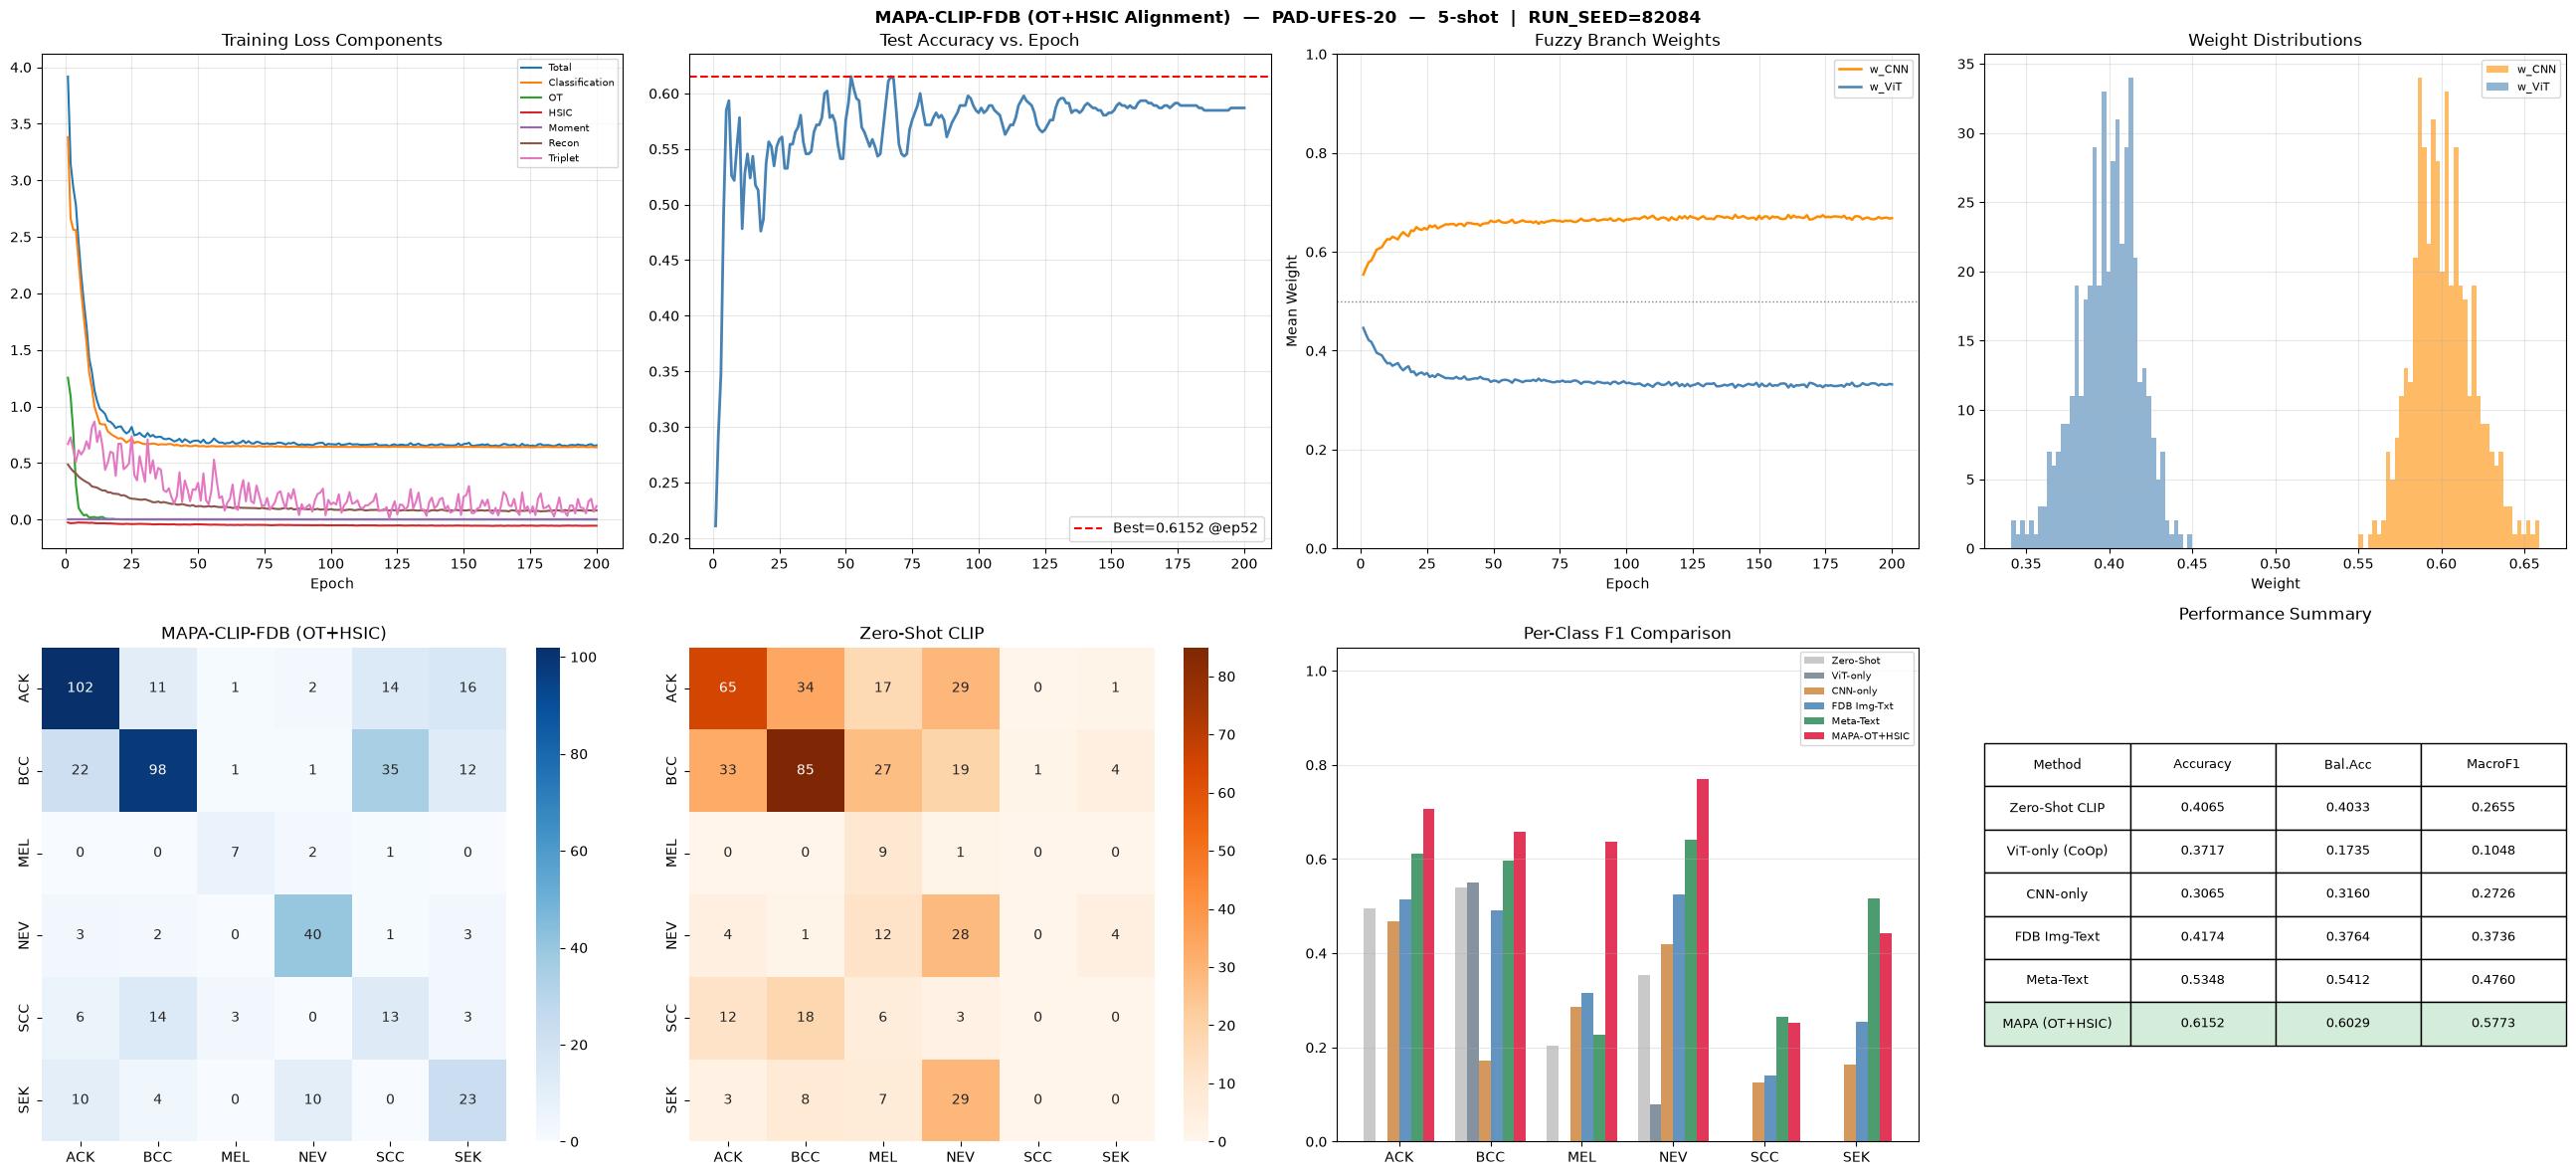

  Plots saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/mapa_clip_fdb_run82084_results.png


In [22]:
print("\nGenerating plots …")

fig, axes = plt.subplots(2, 4, figsize=(26, 12))
fig.suptitle(
    f"MAPA-CLIP-FDB (OT+HSIC Alignment)  —  PAD-UFES-20  —  {N_SHOTS}-shot"
    f"  |  RUN_SEED={RUN_SEED}",
    fontsize=12, fontweight="bold",
)
ep_range = range(1, EPOCHS + 1)

ax = axes[0, 0]
for key, label in [("loss","Total"),("cls","Classification"),
                    ("ot","OT"),("hsic","HSIC"),("moment","Moment"),
                    ("recon","Recon"),("trip","Triplet")]:
    ax.plot(ep_range, hist[key], lw=1.5, label=label)
ax.set_title("Training Loss Components"); ax.set_xlabel("Epoch")
ax.legend(fontsize=7); ax.grid(alpha=0.3)

ax = axes[0, 1]
ax.plot(ep_range, hist["acc"], color="steelblue", lw=2.0)
ax.axhline(best_acc, color="red", ls="--", lw=1.5, label=f"Best={best_acc:.4f} @ep{best_ep}")
ax.set_title("Test Accuracy vs. Epoch"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[0, 2]
ax.plot(ep_range, hist["w_cnn_mean"], color="darkorange", lw=1.8, label="w_CNN")
ax.plot(ep_range, hist["w_vit_mean"], color="steelblue",  lw=1.8, label="w_ViT")
ax.axhline(0.5, color="gray", ls=":", lw=1.0)
ax.set_title("Fuzzy Branch Weights"); ax.set_xlabel("Epoch")
ax.set_ylabel("Mean Weight"); ax.set_ylim(0, 1)
ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[0, 3]
ax.hist(all_wc, bins=40, color="darkorange", alpha=0.6, label="w_CNN")
ax.hist(all_wt, bins=40, color="steelblue",  alpha=0.6, label="w_ViT")
ax.set_title("Weight Distributions")
ax.set_xlabel("Weight"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

sns.heatmap(confusion_matrix(all_labs, all_preds), annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes, ax=axes[1, 0])
axes[1, 0].set_title("MAPA-CLIP-FDB (OT+HSIC)")

sns.heatmap(confusion_matrix(zs_labs, zs_preds), annot=True, fmt="d", cmap="Oranges",
            xticklabels=classes, yticklabels=classes, ax=axes[1, 1])
axes[1, 1].set_title("Zero-Shot CLIP")

f1_zs_pc  = f1_score(zs_labs,  zs_preds,       average=None, labels=list(range(N_CLASSES)))
f1_vit_pc = f1_score(all_labs, vit_only_preds, average=None, labels=list(range(N_CLASSES)))
f1_cnn_pc = f1_score(all_labs, cnn_only_preds, average=None, labels=list(range(N_CLASSES)))
f1_it_pc  = f1_score(all_labs, it_preds,       average=None, labels=list(range(N_CLASSES)))
f1_im_pc  = f1_score(all_labs, im_preds,       average=None, labels=list(range(N_CLASSES)))
f1_fdb_pc = f1_score(all_labs, all_preds,      average=None, labels=list(range(N_CLASSES)))

x = np.arange(N_CLASSES); w = 0.13
for k, (vals, label, color) in enumerate([
    (f1_zs_pc,  "Zero-Shot",  "silver"),
    (f1_vit_pc, "ViT-only",   "slategray"),
    (f1_cnn_pc, "CNN-only",   "peru"),
    (f1_it_pc,  "FDB Img-Txt","steelblue"),
    (f1_im_pc,  "Meta-Text",  "seagreen"),
    (f1_fdb_pc, "MAPA-OT+HSIC","crimson"),
]):
    axes[1, 2].bar(x + (k - 2.5) * w, vals, w, label=label, color=color, alpha=0.85)
axes[1, 2].set_xticks(x); axes[1, 2].set_xticklabels(classes)
axes[1, 2].set_title("Per-Class F1 Comparison")
axes[1, 2].set_ylim(0, 1.05)
axes[1, 2].legend(fontsize=7); axes[1, 2].grid(axis="y", alpha=0.3)

summary = [
    ["Zero-Shot CLIP",
     f"{accuracy_score(zs_labs, zs_preds):.4f}",
     f"{balanced_accuracy_score(zs_labs, zs_preds):.4f}",
     f"{f1_score(zs_labs, zs_preds, average='macro'):.4f}"],
    ["ViT-only (CoOp)",
     f"{accuracy_score(all_labs, vit_only_preds):.4f}",
     f"{balanced_accuracy_score(all_labs, vit_only_preds):.4f}",
     f"{f1_score(all_labs, vit_only_preds, average='macro'):.4f}"],
    ["CNN-only",
     f"{accuracy_score(all_labs, cnn_only_preds):.4f}",
     f"{balanced_accuracy_score(all_labs, cnn_only_preds):.4f}",
     f"{f1_score(all_labs, cnn_only_preds, average='macro'):.4f}"],
    ["FDB Img-Text",
     f"{accuracy_score(all_labs, it_preds):.4f}",
     f"{balanced_accuracy_score(all_labs, it_preds):.4f}",
     f"{f1_score(all_labs, it_preds, average='macro'):.4f}"],
    ["Meta-Text",
     f"{accuracy_score(all_labs, im_preds):.4f}",
     f"{balanced_accuracy_score(all_labs, im_preds):.4f}",
     f"{f1_score(all_labs, im_preds, average='macro'):.4f}"],
    ["MAPA (OT+HSIC)",
     f"{accuracy_score(all_labs, all_preds):.4f}",
     f"{balanced_accuracy_score(all_labs, all_preds):.4f}",
     f"{f1_score(all_labs, all_preds, average='macro'):.4f}"],
]
axes[1, 3].axis("off")
tbl = axes[1, 3].table(
    cellText=summary, colLabels=["Method", "Accuracy", "Bal.Acc", "MacroF1"],
    cellLoc="center", loc="center",
)
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1.0, 2.2)
for col in range(4):
    tbl[(6, col)].set_facecolor("#d4edda")
axes[1, 3].set_title("Performance Summary", pad=20)

plt.tight_layout()
fig_path = f"{OUTPUT_DIR}/mapa_clip_fdb_run{RUN_SEED}_results.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print(f"  Plots saved → {fig_path}")


## 18b. Individual Training Curves (separate figures)
Each training diagnostic as its own figure — easier to inspect/export individually for the paper.


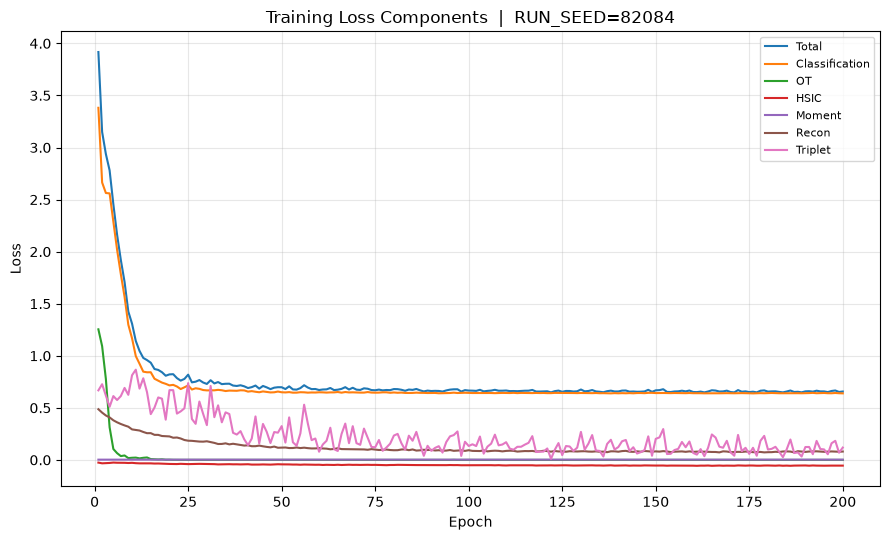

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/loss_components_run82084.png


In [23]:
ep_range = range(1, EPOCHS + 1)

fig = plt.figure(figsize=(9, 5.5))
for key, label in [("loss","Total"),("cls","Classification"),
                    ("ot","OT"),("hsic","HSIC"),("moment","Moment"),
                    ("recon","Recon"),("trip","Triplet")]:
    plt.plot(ep_range, hist[key], lw=1.5, label=label)
plt.title(f"Training Loss Components  |  RUN_SEED={RUN_SEED}")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout()
loss_path = f"{OUTPUT_DIR}/loss_components_run{RUN_SEED}.png"
plt.savefig(loss_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {loss_path}")


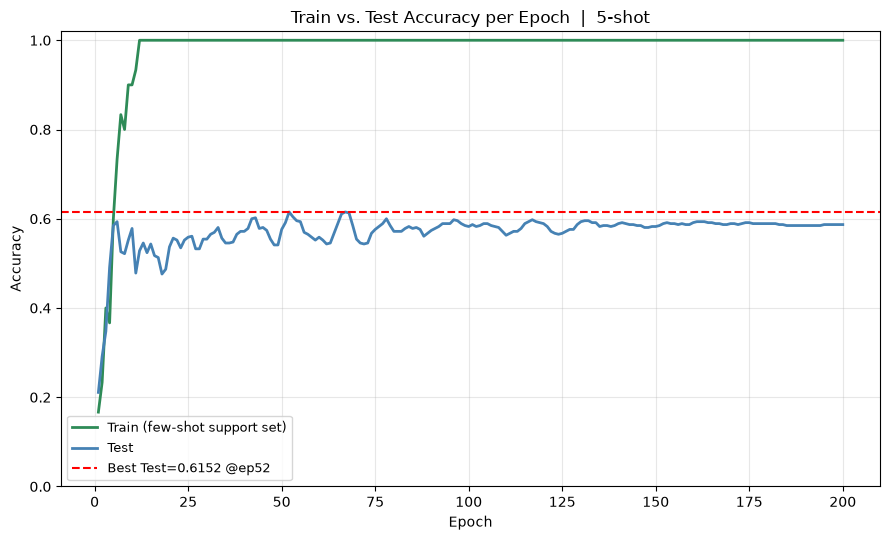

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/train_test_accuracy_run82084.png


In [24]:
fig = plt.figure(figsize=(9, 5.5))
plt.plot(ep_range, hist["train_acc"], color="seagreen", lw=2.0, label="Train (few-shot support set)")
plt.plot(ep_range, hist["acc"], color="steelblue", lw=2.0, label="Test")
plt.axhline(best_acc, color="red", ls="--", lw=1.5, label=f"Best Test={best_acc:.4f} @ep{best_ep}")
plt.title(f"Train vs. Test Accuracy per Epoch  |  {N_SHOTS}-shot")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.ylim(0, 1.02)
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout()
acc_path = f"{OUTPUT_DIR}/train_test_accuracy_run{RUN_SEED}.png"
plt.savefig(acc_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {acc_path}")


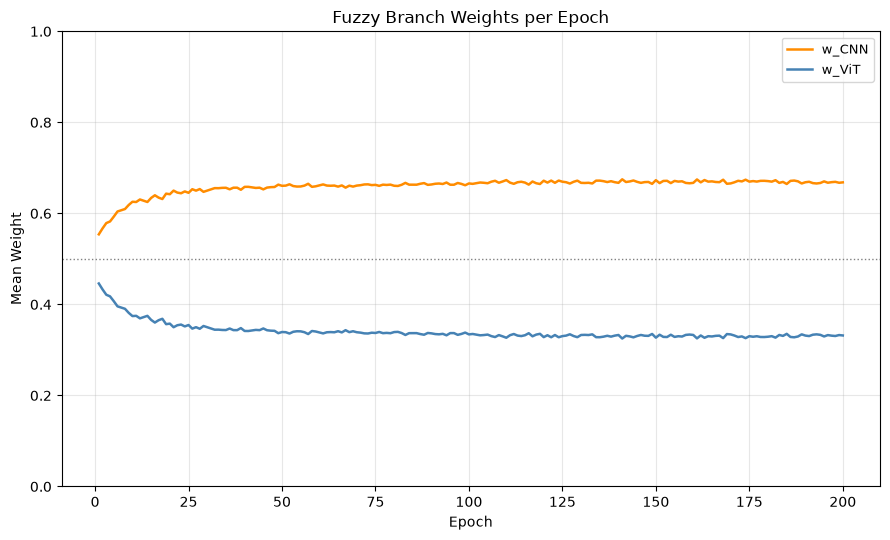

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/fuzzy_weights_epoch_run82084.png


In [25]:
fig = plt.figure(figsize=(9, 5.5))
plt.plot(ep_range, hist["w_cnn_mean"], color="darkorange", lw=1.8, label="w_CNN")
plt.plot(ep_range, hist["w_vit_mean"], color="steelblue",  lw=1.8, label="w_ViT")
plt.axhline(0.5, color="gray", ls=":", lw=1.0)
plt.title("Fuzzy Branch Weights per Epoch")
plt.xlabel("Epoch"); plt.ylabel("Mean Weight"); plt.ylim(0, 1)
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout()
fw_path = f"{OUTPUT_DIR}/fuzzy_weights_epoch_run{RUN_SEED}.png"
plt.savefig(fw_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {fw_path}")


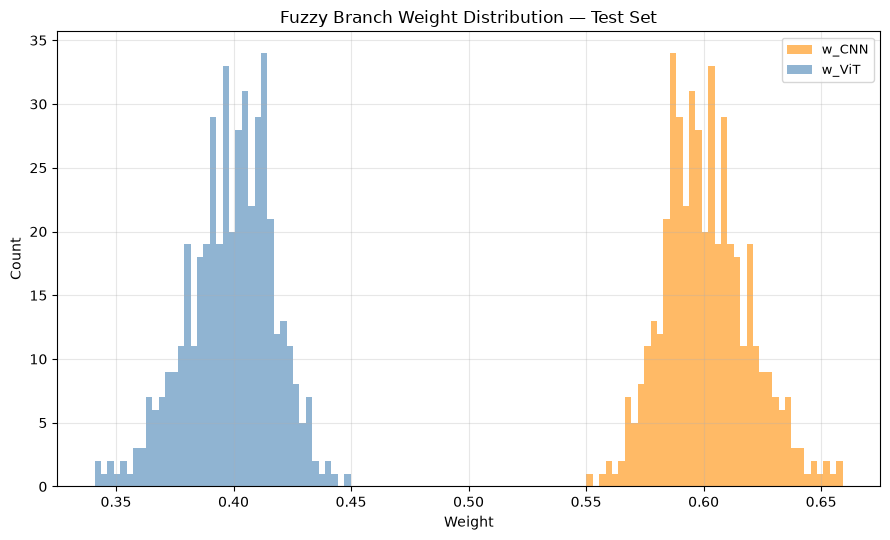

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/fuzzy_weight_dist_run82084.png


In [26]:
fig = plt.figure(figsize=(9, 5.5))
plt.hist(all_wc, bins=40, color="darkorange", alpha=0.6, label="w_CNN")
plt.hist(all_wt, bins=40, color="steelblue",  alpha=0.6, label="w_ViT")
plt.title("Fuzzy Branch Weight Distribution — Test Set")
plt.xlabel("Weight"); plt.ylabel("Count")
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout()
fwd_path = f"{OUTPUT_DIR}/fuzzy_weight_dist_run{RUN_SEED}.png"
plt.savefig(fwd_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {fwd_path}")


## 18c. Confusion Matrices (separate figures)


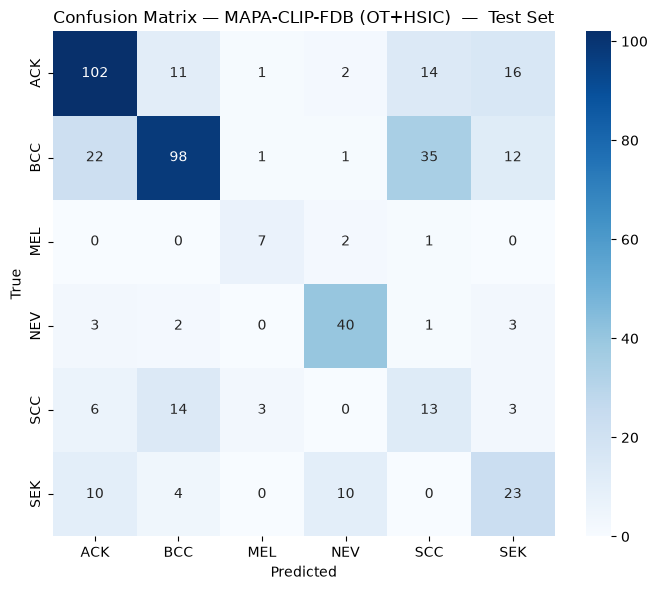

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/confusion_matrix_mapa_run82084.png


In [27]:
fig = plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(all_labs, all_preds), annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix — MAPA-CLIP-FDB (OT+HSIC)  —  Test Set")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
cm_path = f"{OUTPUT_DIR}/confusion_matrix_mapa_run{RUN_SEED}.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {cm_path}")


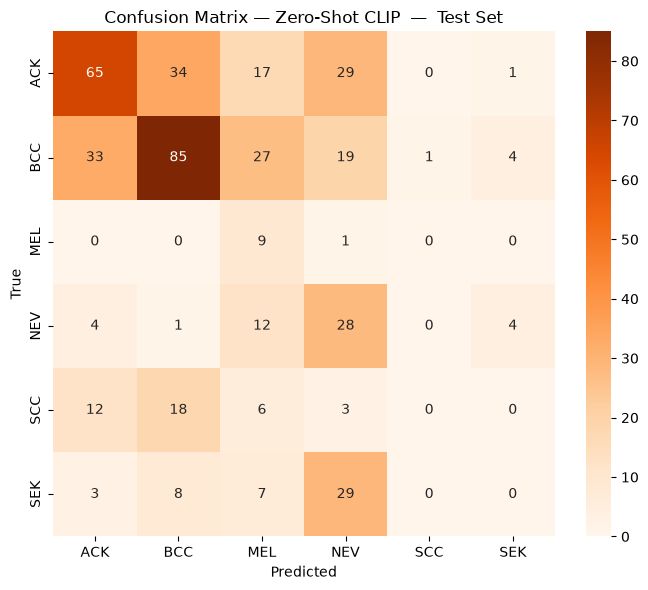

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/confusion_matrix_zeroshot_run82084.png


In [28]:
fig = plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(zs_labs, zs_preds), annot=True, fmt="d", cmap="Oranges",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix — Zero-Shot CLIP  —  Test Set")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
cm_zs_path = f"{OUTPUT_DIR}/confusion_matrix_zeroshot_run{RUN_SEED}.png"
plt.savefig(cm_zs_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {cm_zs_path}")


## 18d. Per-Class F1 Comparison Across Methods


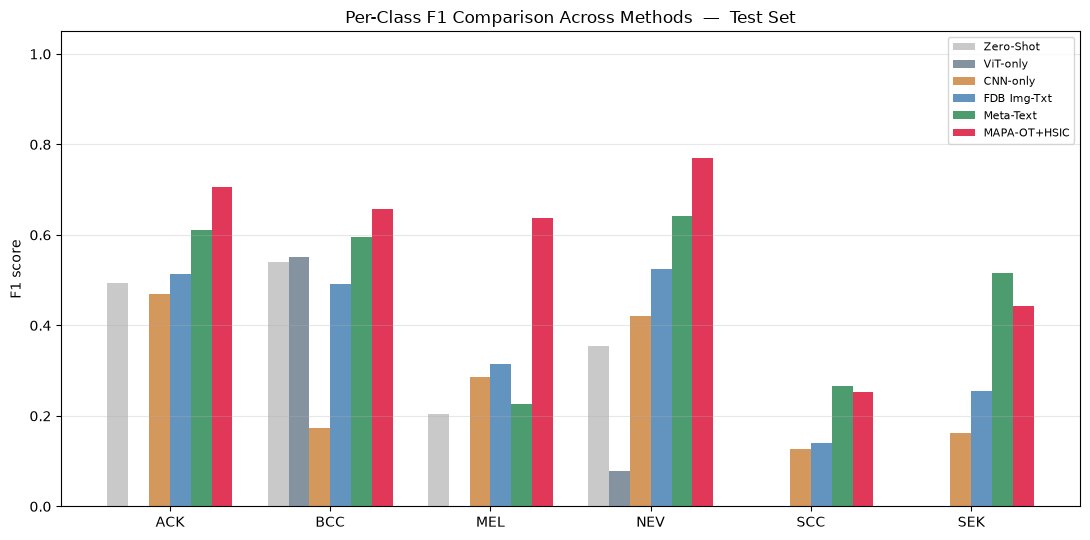

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/per_class_f1_run82084.png


In [29]:
f1_zs_pc  = f1_score(zs_labs,  zs_preds,       average=None, labels=list(range(N_CLASSES)))
f1_vit_pc = f1_score(all_labs, vit_only_preds, average=None, labels=list(range(N_CLASSES)))
f1_cnn_pc = f1_score(all_labs, cnn_only_preds, average=None, labels=list(range(N_CLASSES)))
f1_it_pc  = f1_score(all_labs, it_preds,       average=None, labels=list(range(N_CLASSES)))
f1_im_pc  = f1_score(all_labs, im_preds,       average=None, labels=list(range(N_CLASSES)))
f1_fdb_pc = f1_score(all_labs, all_preds,      average=None, labels=list(range(N_CLASSES)))

fig = plt.figure(figsize=(11, 5.5))
x = np.arange(N_CLASSES); w = 0.13
for k, (vals, label, color) in enumerate([
    (f1_zs_pc,  "Zero-Shot",   "silver"),
    (f1_vit_pc, "ViT-only",    "slategray"),
    (f1_cnn_pc, "CNN-only",    "peru"),
    (f1_it_pc,  "FDB Img-Txt", "steelblue"),
    (f1_im_pc,  "Meta-Text",   "seagreen"),
    (f1_fdb_pc, "MAPA-OT+HSIC","crimson"),
]):
    plt.bar(x + (k - 2.5) * w, vals, w, label=label, color=color, alpha=0.85)
plt.xticks(x, classes)
plt.title("Per-Class F1 Comparison Across Methods  —  Test Set")
plt.ylim(0, 1.05); plt.ylabel("F1 score")
plt.legend(fontsize=8); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
f1_path = f"{OUTPUT_DIR}/per_class_f1_run{RUN_SEED}.png"
plt.savefig(f1_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {f1_path}")


## 18e. ROC / AUC Curves
Multi-class ROC is computed one-vs-rest per class (standard for >2 classes), with micro- and macro-averages.


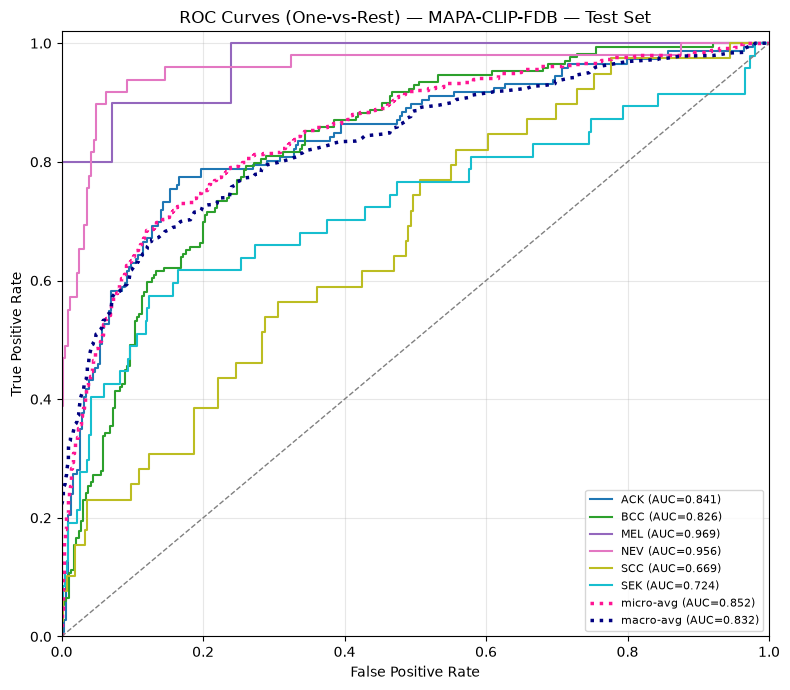

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/roc_curves_run82084.png
  Macro-average AUC: 0.8325   Micro-average AUC: 0.8518


In [30]:
y_bin = label_binarize(all_labs, classes=list(range(N_CLASSES)))

fpr, tpr, roc_auc = {}, {}, {}
for i in range(N_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

fpr["micro"], tpr["micro"], _ = roc_curve(y_bin.ravel(), all_probs.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

_all_fpr = np.unique(np.concatenate([fpr[i] for i in range(N_CLASSES)]))
_mean_tpr = np.zeros_like(_all_fpr)
for i in range(N_CLASSES):
    _mean_tpr += np.interp(_all_fpr, fpr[i], tpr[i])
_mean_tpr /= N_CLASSES
fpr["macro"], tpr["macro"] = _all_fpr, _mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

fig = plt.figure(figsize=(8, 7))
_colors = plt.cm.tab10(np.linspace(0, 1, N_CLASSES))
for i, c in zip(range(N_CLASSES), _colors):
    plt.plot(fpr[i], tpr[i], color=c, lw=1.5, label=f"{classes[i]} (AUC={roc_auc[i]:.3f})")
plt.plot(fpr["micro"], tpr["micro"], color="deeppink", ls=":", lw=2.5,
         label=f"micro-avg (AUC={roc_auc['micro']:.3f})")
plt.plot(fpr["macro"], tpr["macro"], color="navy", ls=":", lw=2.5,
         label=f"macro-avg (AUC={roc_auc['macro']:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, ls="--")
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves (One-vs-Rest) — MAPA-CLIP-FDB — Test Set")
plt.legend(fontsize=8, loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
roc_path = f"{OUTPUT_DIR}/roc_curves_run{RUN_SEED}.png"
plt.savefig(roc_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {roc_path}")
_macro_auc = roc_auc["macro"]; _micro_auc = roc_auc["micro"]
print(f"  Macro-average AUC: {_macro_auc:.4f}   Micro-average AUC: {_micro_auc:.4f}")


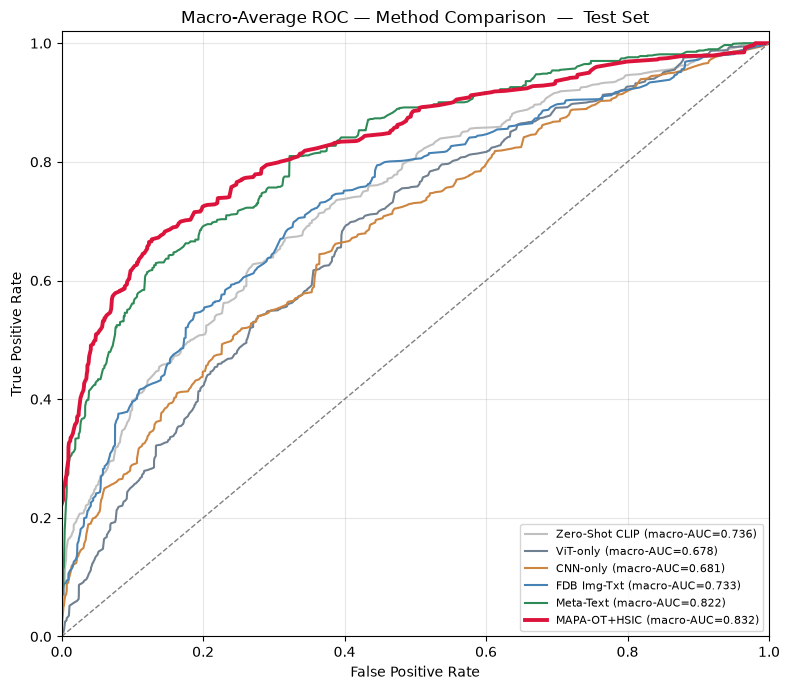

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/roc_comparison_run82084.png


In [31]:
def _macro_roc(y_true_int, probs):
    yb = label_binarize(y_true_int, classes=list(range(N_CLASSES)))
    fprs, tprs = {}, {}
    for i in range(N_CLASSES):
        fprs[i], tprs[i], _ = roc_curve(yb[:, i], probs[:, i])
    all_f = np.unique(np.concatenate([fprs[i] for i in range(N_CLASSES)]))
    mean_t = np.zeros_like(all_f)
    for i in range(N_CLASSES):
        mean_t += np.interp(all_f, fprs[i], tprs[i])
    mean_t /= N_CLASSES
    return all_f, mean_t, auc(all_f, mean_t)

fig = plt.figure(figsize=(8, 7))
for name, labs_, probs_, color in [
    ("Zero-Shot CLIP",  zs_labs,  zs_probs,       "silver"),
    ("ViT-only",        all_labs, vit_only_probs, "slategray"),
    ("CNN-only",        all_labs, cnn_only_probs, "peru"),
    ("FDB Img-Txt",     all_labs, it_probs,       "steelblue"),
    ("Meta-Text",       all_labs, im_probs,       "seagreen"),
    ("MAPA-OT+HSIC",    all_labs, all_probs,      "crimson"),
]:
    f, t, a = _macro_roc(labs_, probs_)
    lw = 2.8 if name == "MAPA-OT+HSIC" else 1.5
    plt.plot(f, t, color=color, lw=lw, label=f"{name} (macro-AUC={a:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, ls="--")
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Macro-Average ROC — Method Comparison  —  Test Set")
plt.legend(fontsize=8, loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
roc_cmp_path = f"{OUTPUT_DIR}/roc_comparison_run{RUN_SEED}.png"
plt.savefig(roc_cmp_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {roc_cmp_path}")


## 18f. Precision-Recall Curves


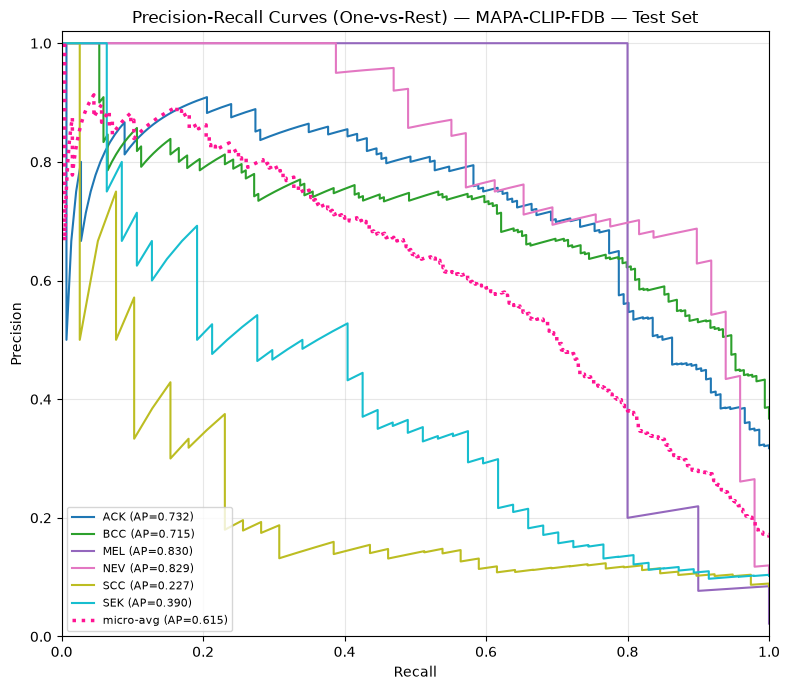

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/pr_curves_run82084.png


In [32]:
precision, recall, ap = {}, {}, {}
for i in range(N_CLASSES):
    precision[i], recall[i], _ = precision_recall_curve(y_bin[:, i], all_probs[:, i])
    ap[i] = average_precision_score(y_bin[:, i], all_probs[:, i])
precision["micro"], recall["micro"], _ = precision_recall_curve(y_bin.ravel(), all_probs.ravel())
ap["micro"] = average_precision_score(y_bin, all_probs, average="micro")

fig = plt.figure(figsize=(8, 7))
for i, c in zip(range(N_CLASSES), _colors):
    plt.plot(recall[i], precision[i], color=c, lw=1.5, label=f"{classes[i]} (AP={ap[i]:.3f})")
plt.plot(recall["micro"], precision["micro"], color="deeppink", ls=":", lw=2.5,
          label=f"micro-avg (AP={ap['micro']:.3f})")
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves (One-vs-Rest) — MAPA-CLIP-FDB — Test Set")
plt.legend(fontsize=8, loc="lower left"); plt.grid(alpha=0.3)
plt.tight_layout()
pr_path = f"{OUTPUT_DIR}/pr_curves_run{RUN_SEED}.png"
plt.savefig(pr_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {pr_path}")


## 18g. Calibration (Reliability Diagram)
How well the predicted probabilities match observed frequencies — important for clinical trustworthiness.


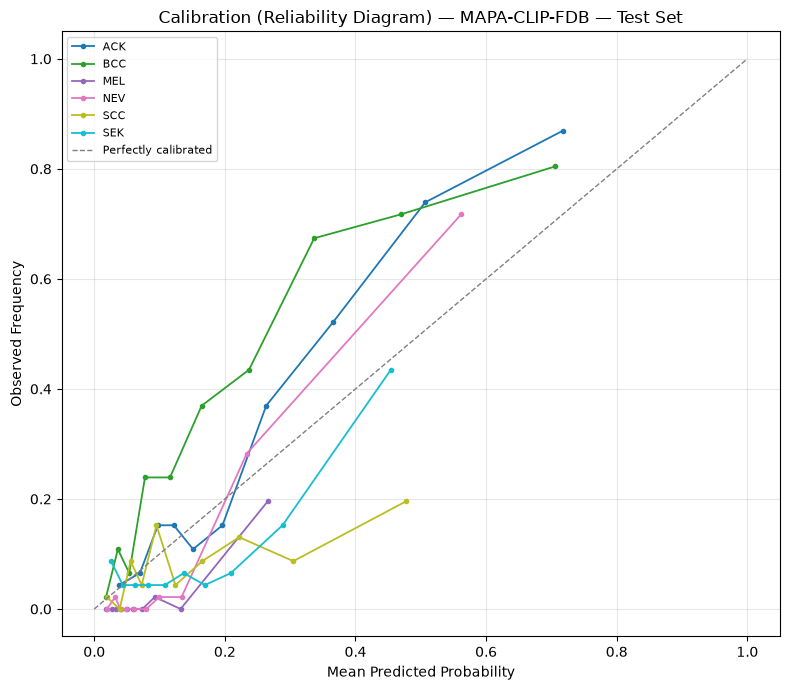

  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/calibration_run82084.png


In [33]:
fig = plt.figure(figsize=(8, 7))
for i, c in zip(range(N_CLASSES), _colors):
    frac_pos, mean_pred = calibration_curve(y_bin[:, i], all_probs[:, i], n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", ms=3, lw=1.3, color=c, label=classes[i])
plt.plot([0, 1], [0, 1], color="gray", lw=1, ls="--", label="Perfectly calibrated")
plt.xlabel("Mean Predicted Probability"); plt.ylabel("Observed Frequency")
plt.title("Calibration (Reliability Diagram) — MAPA-CLIP-FDB — Test Set")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout()
cal_path = f"{OUTPUT_DIR}/calibration_run{RUN_SEED}.png"
plt.savefig(cal_path, dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print(f"  Saved → {cal_path}")


## 18h. Performance Summary Table


In [34]:
summary_df = pd.DataFrame([
    ["Zero-Shot CLIP",  accuracy_score(zs_labs, zs_preds),        balanced_accuracy_score(zs_labs, zs_preds),        f1_score(zs_labs, zs_preds, average="macro")],
    ["ViT-only (CoOp)", accuracy_score(all_labs, vit_only_preds), balanced_accuracy_score(all_labs, vit_only_preds), f1_score(all_labs, vit_only_preds, average="macro")],
    ["CNN-only",        accuracy_score(all_labs, cnn_only_preds), balanced_accuracy_score(all_labs, cnn_only_preds), f1_score(all_labs, cnn_only_preds, average="macro")],
    ["FDB Img-Text",    accuracy_score(all_labs, it_preds),       balanced_accuracy_score(all_labs, it_preds),       f1_score(all_labs, it_preds, average="macro")],
    ["Meta-Text",       accuracy_score(all_labs, im_preds),       balanced_accuracy_score(all_labs, im_preds),       f1_score(all_labs, im_preds, average="macro")],
    ["MAPA (OT+HSIC)",  accuracy_score(all_labs, all_preds),      balanced_accuracy_score(all_labs, all_preds),      f1_score(all_labs, all_preds, average="macro")],
], columns=["Method", "Accuracy", "Balanced Accuracy", "Macro F1"])

summary_path = f"{OUTPUT_DIR}/performance_summary_run{RUN_SEED}.csv"
summary_df.to_csv(summary_path, index=False)
print(f"  Saved → {summary_path}\n")

summary_df.style.background_gradient(
    subset=["Accuracy", "Balanced Accuracy", "Macro F1"], cmap="Greens"
).format({"Accuracy": "{:.4f}", "Balanced Accuracy": "{:.4f}", "Macro F1": "{:.4f}"})


  Saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/performance_summary_run82084.csv



,Method,Accuracy,Balanced Accuracy,Macro F1
0,Zero-Shot CLIP,0.4065,0.4033,0.2655
1,ViT-only (CoOp),0.3717,0.1735,0.1048
2,CNN-only,0.3065,0.3160,0.2726
3,FDB Img-Text,0.4174,0.3764,0.3736
4,Meta-Text,0.5348,0.5412,0.4760
5,MAPA (OT+HSIC),0.6152,0.6029,0.5773


## 19. Embedding PCA


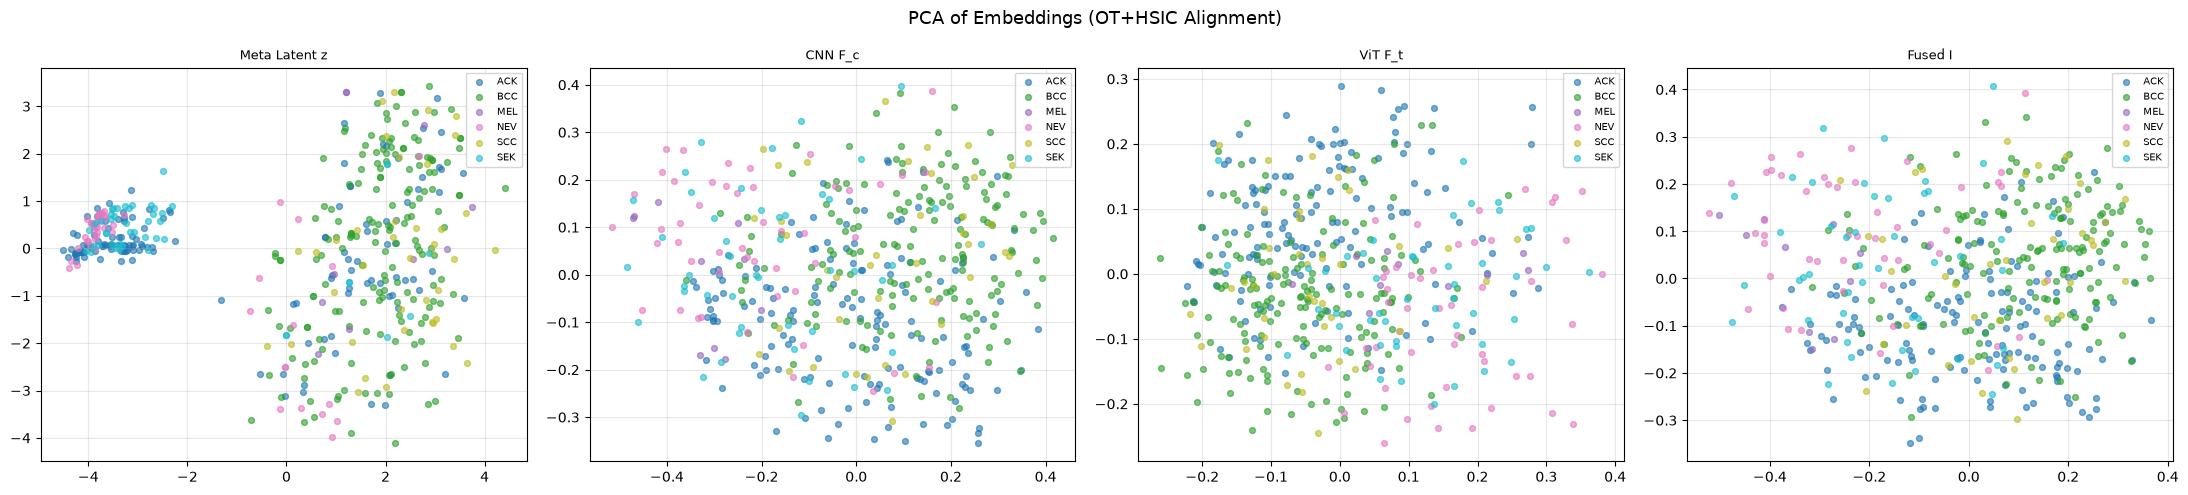

  Embedding PCA saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/embeddings_pca_run82084.png


In [35]:
try:
    from sklearn.decomposition import PCA
    model.eval()
    Z_list, I_list, Fc_list, Ft_list, labs_vis = [], [], [], [], []
    with torch.no_grad():
        for clip_imgs, dense_imgs, meta, labs in test_loader:
            clip_imgs  = clip_imgs.to(DEVICE)
            dense_imgs = dense_imgs.to(DEVICE)
            I, F_c, F_t, _, _ = model._encode_images(clip_imgs, dense_imgs)
            M, z = model._encode_meta(meta.to(DEVICE), recon=False)
            Z_list.append(z.cpu().numpy()); I_list.append(I.cpu().numpy())
            Fc_list.append(F.normalize(F_c, dim=-1).cpu().numpy())
            Ft_list.append(F.normalize(F_t, dim=-1).cpu().numpy())
            labs_vis.extend(labs.numpy())

    labs_vis = np.array(labs_vis)
    pca_z  = PCA(2, random_state=GLOBAL_SEED).fit_transform(np.concatenate(Z_list))
    pca_I  = PCA(2, random_state=GLOBAL_SEED).fit_transform(np.concatenate(I_list))
    pca_fc = PCA(2, random_state=GLOBAL_SEED).fit_transform(np.concatenate(Fc_list))
    pca_ft = PCA(2, random_state=GLOBAL_SEED).fit_transform(np.concatenate(Ft_list))

    colors = plt.cm.tab10(np.linspace(0, 1, N_CLASSES))
    fig2, axs = plt.subplots(1, 4, figsize=(22, 5))
    fig2.suptitle(f"PCA of Embeddings (OT+HSIC Alignment)", fontsize=13)
    for ax, pca_data, title in zip(
        axs, [pca_z, pca_fc, pca_ft, pca_I],
        ["Meta Latent z", "CNN F_c", "ViT F_t", "Fused I"],
    ):
        for k, cls in enumerate(classes):
            mask = labs_vis == k
            ax.scatter(pca_data[mask, 0], pca_data[mask, 1],
                       c=[colors[k]], label=cls, alpha=0.6, s=18)
        ax.set_title(title, fontsize=9); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.tight_layout()
    emb_path = f"{OUTPUT_DIR}/embeddings_pca_run{RUN_SEED}.png"
    plt.savefig(emb_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"  Embedding PCA saved → {emb_path}")
except Exception as e:
    print(f"  [Warning] PCA skipped: {e}")


## 20. Save Predictions


In [36]:
pred_df = pd.DataFrame({
    "img_id":      df.iloc[TEST_IDX][img_col].values,
    "true_label":  [i2c[i] for i in all_labs],
    "pred_label":  [i2c[i] for i in all_preds],
    "correct":     (all_preds == all_labs),
    "fuzzy_w_cnn": all_wc,
    "fuzzy_w_vit": all_wt,
    "run_seed":    RUN_SEED,
    **{f"prob_{c}": all_probs[:, k] for k, c in enumerate(classes)},
})
pred_path = f"{OUTPUT_DIR}/test_predictions_run{RUN_SEED}.csv"
pred_df.to_csv(pred_path, index=False)
print(f"  Predictions saved → {pred_path}")


  Predictions saved → /home/talha_k/Downloads/MAPA-CLIP-FDB/output/test_predictions_run82084.csv


## 21. Done / Summary


In [37]:
print(f"\n{'='*60}\nDONE\n{'='*60}")
print(f"  GLOBAL_SEED : {GLOBAL_SEED}")
print(f"  RUN_SEED    : {RUN_SEED}")
print(f"  Best accuracy        : {best_acc:.4f}  (epoch {best_ep})")
print(f"  Zero-shot baseline   : {accuracy_score(zs_labs, zs_preds):.4f}")
print(f"  Improvement          : +{best_acc - accuracy_score(zs_labs, zs_preds):.4f}")
print(f"\n  ★ Novel Alignment: Optimal Transport + HSIC (NO contrastive loss)")
print(f"    This approach aligns vision-text distributions geometrically")
print(f"    while maximizing within-class dependence via HSIC.")



DONE
  GLOBAL_SEED : 42
  RUN_SEED    : 82084
  Best accuracy        : 0.6152  (epoch 52)
  Zero-shot baseline   : 0.4065
  Improvement          : +0.2087

  ★ Novel Alignment: Optimal Transport + HSIC (NO contrastive loss)
    This approach aligns vision-text distributions geometrically
    while maximizing within-class dependence via HSIC.
